# **Previsao de Secas no Estado com Modelos SPI**

Neste ambiente de codificacao do Google Colab, estaremos utilizando Machine Learning para prever focos de seca no estado de Mato Grosso, nossas areas de estudo foram os municipios de:


*   Sorriso

*   Primavera do Leste



Um dos primeiros passos para nosso estudo e a importacao das bibliotecas que usaremos em nossos modelos



In [ ]:
!pip install earthengine-api geemap

import ee
import geemap
import pandas as pd
import datetime
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import requests
import time
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

from google.colab import drive
from statsmodels.stats.anova import anova_lm
from scipy.stats import zscore
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import Huber
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.0 MB/s eta 0:00:00


In [ ]:
ee.Authenticate()
ee.Initialize(project='projeto-tcc-matheus')

**Baixando e Convertendo Dados do NOAA**
Nem toda informação vem do GEE. Este bloco faz um web scraping direto do site da NOAA para obter o índice ONI (Oceanic Niño Index), que mede a intensidade do El Niño e La Niña, fatores cruciais para as chuvas no MT.

In [ ]:
url = "https://psl.noaa.gov/data/correlation/oni.data"

response = requests.get(url)
texto = response.text

linhas = texto.split('\n')

dados = []

for linha in linhas:
    partes = linha.split()

    if len(partes) == 13:
        ano = int(partes[0])
        valores = partes[1:]

        for mes, val in enumerate(valores, start=1):
            try:
                dados.append({
                    'ano': ano,
                    'mes': mes,
                    'ENSO': float(val)
                })
            except:
                pass

df_enso = pd.DataFrame(dados)

df_enso = df_enso[
    (df_enso['ano'] >= 2000) &
    (df_enso['ano'] <= 2026)
]

Processamento de bandas do Landsat 7 e 8 para que filtre somente:


NDVI
*   bandas 4 e 3 do Landsat 7
*   bandas 5 e 4 do Landsat 8

LST

*   bandas 10 e 8 do Landsat 8


In [ ]:
def processar_landsat(img, is_l8=False):

    qa = img.select('QA_PIXEL')
    mask = qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0))


    opticos = img.select('SR_B.*').multiply(0.0000275).add(-0.2)
    termico = img.select('ST_B.*').multiply(0.00341802).add(149.0)

    nir = 'SR_B5' if is_l8 else 'SR_B4'
    red = 'SR_B4' if is_l8 else 'SR_B3'
    banda_termica = 'ST_B10' if is_l8 else 'ST_B6'

    ndvi = opticos.normalizedDifference([nir, red]).rename('NDVI_L')
    lst = termico.select([banda_termica], ['LST'])

    return img.addBands([ndvi, lst]).updateMask(mask)

# **Sorriso**

Vamos delimitar nossa area de estudo. Neste primeiro caso sera o Municipio de Sorriso - MT. Definicao dos pontos agricolas

In [ ]:
municipios = ee.FeatureCollection("FAO/GAUL/2015/level2")

municipio1 = (
    municipios
    .filter(ee.Filter.eq('ADM1_NAME','Mato Grosso'))
    .filter(ee.Filter.eq('ADM2_NAME','Sorriso'))
)

coordenadas = [[-55.482996, -13.197328],[-55.734344, -12.545209],[-55.763895, -11.828915],[-55.212295, -13.489647],[-55.848502, -13.176305]]

features = []

for i, coord in enumerate(coordenadas):
  geometria = ee.Geometry.Point(coord)
  feat = ee.Feature(geometria, {'id': i+1, 'nome':f'Ponto_{i+1}'})
  features.append(feat)

pontos = ee.FeatureCollection(features)

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


Utilizando dados disponibilizados pelo Central Perigos Climaticos (Climate Hazard Center) ou Chirps, filtraremos os dados entre os anos de 2000 a 2025 (25 anos de dados)

Coletar dados climáticos (ERA5 + CHIRPS), NDVI

In [ ]:
era5 = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterBounds(pontos)
    .filterDate('2000-01-01','2026-04-30')
)

era5_diario = (
    ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
    .filterBounds(pontos)
    .filterDate('2000-01-01','2026-04-30')
)

chuva = (
    ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
    .filterBounds(municipio1)
    .filterDate('2000-01-01','2026-04-30')
)

ndvi_col = (
    ee.ImageCollection("MODIS/061/MOD13Q1")
    .filterBounds(municipio1)
    .filterDate('2000-01-01','2026-04-30')
)

Abaixo utilizamos os satelites Landsat 7 e 8 para medir a temperatura da superficie terrestre LST juntamente com o ndvi para agregar ao satelite utilizado ateriormente MODIS

In [ ]:
landsat7 = (
    ee.ImageCollection("LANDSAT/LE07/C02/T1_L2")
    .filterBounds(municipio1)
    .filterDate('2000-01-01', '2026-04-30')
    .map(lambda img: processar_landsat(img, is_l8=False))
    .select(['NDVI_L', 'LST'])
)

landsat8 = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(municipio1)
    .filterDate('2000-01-01', '2026-04-30')
    .map(lambda img: processar_landsat(img, is_l8=True))
    .select(['NDVI_L', 'LST'])
)

landsat_total = landsat7.merge(landsat8)

A seguir Geramos um mapa interativo dentro do notebook para inspeção visual. Ele plota o limite do município, os pontos escolhidos. Podemos escolher visualizar o NDVI, a Temperatura do Solo ou o Volume de Chuva durante os anos 2000,2005,2010,2015,2020 e 2025.

# **Visualizador de Volume Anual de Chuva**

In [ ]:
chuva_random = chuva.randomColumn('random')
amostra = chuva_random.sort('random').limit(10)

datas = amostra.aggregate_array('system:time_start').getInfo()
for d in datas:
    print(datetime.datetime.utcfromtimestamp(d/1000))

Map = geemap.Map()
Map.centerObject(municipio1,8)
Map.addLayer(municipio1,{},"Municipio")

for i in range(3):
  img = ee.Image(amostra.toList(3).get(i))

  Map.addLayer(
      img.clip(municipio1),
      {'min':0,'max':50,'palette':['white','blue','purple']},
      f'Chuva {i+1}'
  )
  Map.addLayer(
      pontos, {'color': 'red'},
      'Pontos'
  )

Map

/tmp/ipykernel_1948/4179661524.py:6: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  print(datetime.datetime.utcfromtimestamp(d/1000))


2020-10-01 00:00:00
2005-06-03 00:00:00
2019-08-14 00:00:00
2010-10-03 00:00:00
2012-05-25 00:00:00
2020-07-09 00:00:00
2004-09-22 00:00:00
2013-08-26 00:00:00
2016-12-18 00:00:00
2015-09-15 00:00:00


Map(center=[-12.73563592862483, -55.68104822644539], controls=(WidgetControl(options=['position', 'transparent…

# **Visualizador de NDVI**

In [ ]:
anos_ndvi = [2000, 2005, 2010, 2015, 2020, 2025]

paleta_ndvi = [
    '#d73027', '#f46d43', '#fdae61', '#fee08b',
    '#d9ef8b', '#a6d96a', '#66bd63', '#1a9850'
]

Map = geemap.Map()
Map.centerObject(municipio1, 8)
Map.addLayer(municipio1, {}, "Limites - Sorriso", False)


for ano in anos_ndvi:
    inicio = f'{ano}-01-01'
    fim = f'{ano}-12-31'

    ndvi_anual = (
        ndvi_col
        .filterDate(inicio, fim)
        .select('NDVI')
        .median()
        .clip(municipio1)
    )

    Map.addLayer(
        ndvi_anual,
        {'min': 0, 'max': 8000, 'palette': paleta_ndvi},
        f'NDVI MODIS - {ano}',
        shown=False
    )

Map.addLayer(pontos, {'color': 'red'}, 'Pontos de Estudo')


Map

Map(center=[-12.735635928624818, -55.68104822644536], controls=(WidgetControl(options=['position', 'transparen…

# **Visualizador de Temperatura**

In [ ]:
anos_mapa = [2000, 2005, 2010, 2015, 2020, 2025]

paleta_calor = [
    '#313695', '#74add1', '#ffffbf', '#f46d43', '#a50026']

MapaCalor = geemap.Map()
MapaCalor.centerObject(municipio1, 8)
MapaCalor.addLayer(municipio1, {}, "Limites - Sorriso", False)


for ano in anos_mapa:
    inicio = f'{ano}-01-01'
    fim = f'{ano}-12-31'

    temperatura_anual = (
        landsat_total
        .filterDate(inicio, fim)
        .select('LST')
        .mean()
        .subtract(273.15)
        .clip(municipio1)
    )

    MapaCalor.addLayer(
        temperatura_anual,
        {'min': 25, 'max': 45, 'palette': paleta_calor},
        f'Temp Média (°C) - {ano}',
        shown=False
    )

MapaCalor.addLayer(pontos, {'color': 'green'}, 'Pontos de Estudo')


MapaCalor

Map(center=[-12.735635928624818, -55.68104822644536], controls=(WidgetControl(options=['position', 'transparen…

In [ ]:
pontos_info = pontos.getInfo()['features']
anos = list(range(2000,2027))
meses = list(range(1,13))

# **Balanço de Dados e Treinamento**

In [ ]:
data_inicio = '2000-01-01'
data_fim = '2026-04-30'
era5 = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").filterBounds(pontos).filterDate(data_inicio, data_fim)
era5_diario = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR").filterBounds(pontos).filterDate(data_inicio, data_fim)
chuva = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").filterBounds(municipio1).filterDate(data_inicio, data_fim)
ndvi_modis = ee.ImageCollection("MODIS/061/MOD13Q1").filterBounds(municipio1).filterDate(data_inicio, data_fim)


dados_balanco = [
    {"Sensor / Produto": "Landsat 7 (Superfície)", "Resolução": "30m", "Temporalidade": "16 dias", "Total Imagens": landsat7.size().getInfo()},
    {"Sensor / Produto": "Landsat 8 (Superfície)", "Resolução": "30m", "Temporalidade": "16 dias", "Total Imagens": landsat8.size().getInfo()},
    {"Sensor / Produto": "MODIS NDVI (MOD13Q1)", "Resolução": "250m", "Temporalidade": "16 dias", "Total Imagens": ndvi_modis.size().getInfo()},
    {"Sensor / Produto": "CHIRPS (Precipitação)", "Resolução": "5500m", "Temporalidade": "Diário", "Total Imagens": chuva.size().getInfo()},
    {"Sensor / Produto": "ERA5-Land (Temperatura Mensal)", "Resolução": "11132m", "Temporalidade": "Mensal", "Total Imagens": era5.size().getInfo()},
    {"Sensor / Produto": "ERA5-Land (Temperatura Diária)", "Resolução": "11132m", "Temporalidade": "Diário", "Total Imagens": era5_diario.size().getInfo()},
]


df_balanco = pd.DataFrame(dados_balanco)
print("\n--- BALANÇO GERAL DE IMAGENS POR SENSOR (2000 a 2026) ---")
print(df_balanco.to_string(index=False))


--- BALANÇO GERAL DE IMAGENS POR SENSOR (2000 a 2026) ---
              Sensor / Produto Resolução Temporalidade  Total Imagens
        Landsat 7 (Superfície)       30m       16 dias           2084
        Landsat 8 (Superfície)       30m       16 dias           1196
          MODIS NDVI (MOD13Q1)      250m       16 dias            603
         CHIRPS (Precipitação)     5500m        Diário           9616
ERA5-Land (Temperatura Mensal)    11132m        Mensal            316
ERA5-Land (Temperatura Diária)    11132m        Diário           9616


In [ ]:
# --- NOVO CÓDIGO: BALANÇO DE IMAGENS POR ANO ---

# Criar uma lista de anos no servidor do Earth Engine (2000 a 2026)
anos_ee = ee.List.sequence(2000, 2026)
anos_python = list(range(2000, 2027))

def contar_por_ano(colecao):
    """Filtra a coleção por ano no servidor e retorna a contagem."""
    def conta_ano(ano):
        # Filtra as imagens que caem naquele ano específico
        filtro_ano = colecao.filter(ee.Filter.calendarRange(ano, ano, 'year'))
        return filtro_ano.size()

    # Mapeia a contagem para todos os anos e extrai o resultado (getInfo) uma única vez
    return anos_ee.map(conta_ano).getInfo()

print("\nProcessando contagem anual... (isso pode levar alguns segundos)")

# Coletando os dados anuais para cada sensor/coleção
dados_anuais = {
    'Ano': anos_python,
    'Landsat 7': contar_por_ano(landsat7),
    'Landsat 8': contar_por_ano(landsat8), # Retornará 0 antes de 2013
    'MODIS NDVI': contar_por_ano(ndvi_modis),
    'CHIRPS': contar_por_ano(chuva),
    'ERA5 (Mensal)': contar_por_ano(era5),
    'ERA5 (Diário)': contar_por_ano(era5_diario)
}

# Criando o DataFrame
df_anual = pd.DataFrame(dados_anuais)

# Adicionando uma linha com o TOTAL no final do DataFrame
df_anual.loc['Total'] = df_anual.sum(numeric_only=True)
df_anual.at['Total', 'Ano'] = 'TOTAL'

print("\n--- BALANÇO DE IMAGENS CAPTADAS POR ANO (2000 a 2026) ---")
print(df_anual.to_string(index=False))


Processando contagem anual... (isso pode levar alguns segundos)

--- BALANÇO DE IMAGENS CAPTADAS POR ANO (2000 a 2026) ---
  Ano  Landsat 7  Landsat 8  MODIS NDVI  CHIRPS  ERA5 (Mensal)  ERA5 (Diário)
 2000         84          0          20     366             12            366
 2001         88          0          23     365             12            365
 2002         90          0          23     365             12            365
 2003         56          0          23     365             12            365
 2004         92          0          23     366             12            366
 2005         90          0          23     365             12            365
 2006         88          0          23     365             12            365
 2007         93          0          23     365             12            365
 2008         81          0          23     366             12            366
 2009         98          0          23     365             12            365
 2010         85  

Dados Diarios para calculo de ondas de calor

In [ ]:
def calcular_heat_wave(img):

    temp_c = img.select('temperature_2m').subtract(273.15)

    hot = temp_c.gt(32)

    return img.addBands(hot.rename('hot_day'))


era5_hot = era5_diario.map(calcular_heat_wave)

def heat_wave_mensal(ano, mes, geom):

    inicio = ee.Date.fromYMD(ano, mes, 1)
    fim = inicio.advance(1, 'month')

    coleção = era5_hot.filterDate(inicio, fim)

    soma = ee.Image(
        ee.Algorithms.If(
            coleção.size().gt(0),
            coleção.select('hot_day').sum(),
            ee.Image(-9999).rename('hot_day') # Cria uma imagem falsa com o valor de erro
        )
    )

    valor = soma.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geom,
        scale=10000,
        maxPixels=1e9
    )

    return valor.get('hot_day',-9999)

**Dados Mensais**
Esta é a etapa mais pesada de processamento. O código itera sobre cada ano, cada mês e cada ponto, transformando os "pixels" das imagens de satélite em valores numéricos (tabular) usando o reduceRegion. Por fim, exporta a tabela para o Google Drive.

In [ ]:
features = []

for p in pontos_info:

    geom = ee.Geometry.Point(p['geometry']['coordinates'])
    pid = p['id'] if 'id' in p else None

    print(f"Processando ponto {pid}...")

    for ano in anos:
      for mes in meses:

            inicio = ee.Date.fromYMD(ano, mes, 1)
            fim = inicio.advance(1, 'month')

            # CHUVA
            #chuva_img = chuva.filterDate(inicio, fim).sum()
            chuva_filtrada = chuva.filterDate(inicio, fim)
            chuva_img = ee.Image(
                ee.Algorithms.If(
                    chuva_filtrada.size().gt(0),
                    chuva_filtrada.sum(),
                    ee.Image(-9999).rename('precipitation')
                )
            )

            # TEMPERATURA
            #temp_img = era5.filterDate(inicio, fim).mean()
            temp_filtrada = era5.filterDate(inicio, fim)
            temp_img = ee.Image(
                ee.Algorithms.If(
                    temp_filtrada.size().gt(0),
                    temp_filtrada.mean(),
                    ee.Image(-9999).rename('temperature_2m')
                )
            )

            heat_val = heat_wave_mensal(ano, mes, geom)

            # NDVI
            ndvi_MODIS_filtrado = ndvi_col.filterDate(inicio, fim)
            ndvi_MODIS_img = ee.Image(
              ee.Algorithms.If(
                ndvi_MODIS_filtrado.size().gt(0),
                ndvi_MODIS_filtrado.mean(),
              ee.Image(-9999).rename('NDVI')
              )
            )

            #Landsat
            landsat_f = landsat_total.filterDate(inicio, fim)
            landsat_img = ee.Image(
                ee.Algorithms.If(
                    landsat_f.size().gt(0),
                    landsat_f.mean(),
                    ee.Image(-9999).addBands(ee.Image(-9999)).rename(['NDVI_L', 'LST'])
                )
            )

            # EXTRAÇÃO PONTO A PONTO
            chuva_val = chuva_img.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=geom,
                scale=5000,
                maxPixels=1e9,
                bestEffort=True
            )

            temp_val = temp_img.select('temperature_2m').reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=geom,
                scale=11132
            )

            ndvi_MODIS_val = ndvi_MODIS_img.select('NDVI').reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=municipio1,
                scale=250,
                maxPixels=1e9
            )

            landsat_val = landsat_img.select(['NDVI_L', 'LST']).reduceRegion(
                reducer=ee.Reducer.mean(), geometry=geom, scale=30
            )

            feat = ee.Feature(None, {
                'ponto': pid,
                'ano': ano,
                'mes': mes,
                'prec': chuva_val.get('precipitation', -9999),
                'temp': temp_val.get('temperature_2m', -9999),
                'ndvi': ndvi_MODIS_val.get('NDVI', -9999),
                'heat_wave': heat_val,
                'ndvi_landsat': landsat_val.get('NDVI_L', -9999),
                'lst_landsat': landsat_val.get('LST', -9999)
            })

            features.append(feat)

Processando ponto 0...
Processando ponto 1...
Processando ponto 2...
Processando ponto 3...
Processando ponto 4...


Exportamos o arquivo do earth code para nosso drive em formato csv, e aguardamos ate o processo ser finalizado

In [ ]:
fc = ee.FeatureCollection(features)

task = ee.batch.Export.table.toDrive(
    collection=fc,
    description='Sorriso_dados_agro_vFinalfinal',
    fileFormat='CSV'
)

task.start()


while task.active():
    print(task.status())
    time.sleep(60)


print(task.status())

{'state': 'READY', 'description': 'Sorriso_dados_agro_vFinalfinal', 'priority': 100, 'creation_timestamp_ms': 1792256172563, 'update_timestamp_ms': 1792256172563, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'NPO7INXAFFX6SI2AUSUNNCKJ', 'name': 'projects/projeto-tcc-matheus/operations/NPO7INXAFFX6SI2AUSUNNCKJ'}
{'state': 'RUNNING', 'description': 'Sorriso_dados_agro_vFinalfinal', 'priority': 100, 'creation_timestamp_ms': 1792256172563, 'update_timestamp_ms': 1792256224991, 'start_timestamp_ms': 1792256174766, 'task_type': 'EXPORT_FEATURES', 'attempt': 1, 'batch_eecu_usage_seconds': 26.104963302, 'id': 'NPO7INXAFFX6SI2AUSUNNCKJ', 'name': 'projects/projeto-tcc-matheus/operations/NPO7INXAFFX6SI2AUSUNNCKJ'}
{'state': 'RUNNING', 'description': 'Sorriso_dados_agro_vFinalfinal', 'priority': 100, 'creation_timestamp_ms': 1792256172563, 'update_timestamp_ms': 1792256284991, 'start_timestamp_ms': 1792256174766, 'task_type': 'EXPORT_FEATURES', 'attempt': 1, 'batch_eecu_usage_seco

Ao finalizar o processo acessamos o Drive para a leitura do arquivo criado e juntamos com a tabela do El Niño.


In [ ]:
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Sorriso_dados_agro_vFinalfinal.csv')
df = df.replace(-9999, np.nan)



df['prec'] = df['prec'].interpolate(method='linear')
df['temp'] = df['temp'].interpolate(method='linear')
df['ndvi'] = df['ndvi'].interpolate(method='linear')
df['ndvi_landsat'] = df['ndvi_landsat'].interpolate(method='linear')
df['lst_landsat'] = df['lst_landsat'].interpolate(method='linear')


df = df.drop(columns=['system:index', '.geo'])
df = df.merge(df_enso, on=['ano','mes'], how='left')
df = df.sort_values(['ponto', 'ano', 'mes']).reset_index(drop=True)

print(df.head())

Mounted at /content/drive
    ano  heat_wave  lst_landsat  mes         ndvi  ndvi_landsat  ponto  \
0  2000        0.0          NaN    1          NaN           NaN      0   
1  2000        0.0   287.494752    2  5742.181655      0.527543      0   
2  2000        0.0   299.685121    3  5672.828421      0.485944      0   
3  2000        0.0   311.875489    4  6657.022677      0.444345      0   
4  2000        0.0   310.662092    5  6262.331963      0.483217      0   

         prec        temp  ENSO  
0  277.093377  297.327945 -1.47  
1  286.185138  297.306228 -1.26  
2  191.894653  297.387646 -0.98  
3  107.661859  297.625660 -0.81  
4    6.727114  298.011498 -0.67  


 O passo mais importante aqui é o cálculo do SPI (Índice de Precipitação Padronizada). Ele acumula a chuva em janelas de 3 e 6 meses (rolling) e aplica o Z-score para determinar matematicamente se a fazenda está em seca (valores negativos) ou cheia (valores positivos).

In [ ]:
df['SPI1'] = df.groupby('ponto')['prec'].transform(lambda x: zscore(x, nan_policy='omit'))

df['prec_3'] = df.groupby('ponto')['prec'].rolling(3).sum().reset_index(level=0, drop=True)
df['SPI3'] = df.groupby('ponto')['prec_3'].transform(lambda x: zscore(x, nan_policy='omit'))


df['prec_6'] = df.groupby('ponto')['prec'].rolling(6).sum().reset_index(level=0, drop=True)
df['SPI6'] = df.groupby('ponto')['prec_6'].transform(lambda x: zscore(x, nan_policy='omit'))

df = df.round(3)

In [ ]:
####################################

df_spis = df[['ponto', 'ano', 'mes', 'SPI1', 'SPI3']].copy()

df_spis = df_spis.dropna()

# 4. Mostrar as primeiras linhas no terminal para você conferir
print("\n--- Visualização da Tabela de SPIs ---")
print(df_spis.head())

# 5. Exportar para o Google Drive (na mesma pasta do seu arquivo original)
caminho_salvar = '/content/drive/MyDrive/Sorriso_SPI_Calculados_v2.csv'
df_spis.to_csv(caminho_salvar, index=False)

print(f"\nArquivo de SPIs salvo com sucesso em: {caminho_salvar}")

##############################################################


--- Visualização da Tabela de SPIs ---
   ponto   ano  mes   SPI1   SPI3
2      0  2000    3  0.294  0.876
3      0  2000    4 -0.353  0.376
4      0  2000    5 -1.129 -0.450
5      0  2000    6 -1.140 -1.001
6      0  2000    7 -1.180 -1.319

Arquivo de SPIs salvo com sucesso em: /content/drive/MyDrive/Sorriso_SPI_Calculados_v2.csv


In [ ]:
# resultado da precipitacao mensal do municipio em mm
print(df.head(10))

    ano  heat_wave  lst_landsat  mes      ndvi  ndvi_landsat  ponto     prec  \
0  2000        0.0          NaN    1       NaN           NaN      0  277.093   
1  2000        0.0      287.495    2  5742.182         0.528      0  286.185   
2  2000        0.0      299.685    3  5672.828         0.486      0  191.895   
3  2000        0.0      311.875    4  6657.023         0.444      0  107.662   
4  2000        0.0      310.662    5  6262.332         0.483      0    6.727   
5  2000        0.0      303.732    6  5317.780         0.277      0    5.288   
6  2000        0.0      310.799    7  5010.421         0.150      0    0.000   
7  2000        0.0      318.718    8  4783.687         0.164      0    4.348   
8  2000        0.0      318.541    9  5163.914         0.144      0   79.204   
9  2000        0.0      316.358   10  5042.673         0.183      0   98.652   

      temp  ENSO   SPI1   prec_3   SPI3   prec_6   SPI6  
0  297.328 -1.47  0.949      NaN    NaN      NaN    NaN  
1  

**Criacao do Alvo de precisao de Sorriso**
Redimensiona o NDVI para escala real, converte temperatura de Kelvin para Celsius, e cria os Lags (atrasos). Como é uma série temporal, a chuva do passado ajuda a prever o futuro. O código cria 24 colunas de SPI passado (mês passado, 2 meses atrás, etc.).

In [ ]:
df['SPI3_future'] = df.groupby('ponto')['SPI3'].shift(-3)

df['ndvi'] = df['ndvi'] / 10000 # Normalizar NDVI
df['temp'] = df['temp'] - 273.15 # Converter temperatura (Kelvin para Celsius)
df['lst_landsat'] = df['lst_landsat'] - 273.15
df['ENSO'] = df['ENSO'].interpolate()

#df['ndvi_combinado'] = df[['ndvi_modis', 'ndvi_landsat']].mean(axis=1)

print(df[['ano','mes','ENSO']].head(15))

lags =  24 # 24 meses

for i in range(1, lags + 1):
    df[f'SPI3_lag_{i}'] = df.groupby('ponto')['SPI3'].shift(i)

df = df.dropna().reset_index(drop=True)

print(df.isna().sum())

     ano  mes  ENSO
0   2000    1 -1.47
1   2000    2 -1.26
2   2000    3 -0.98
3   2000    4 -0.81
4   2000    5 -0.67
5   2000    6 -0.62
6   2000    7 -0.48
7   2000    8 -0.40
8   2000    9 -0.42
9   2000   10 -0.54
10  2000   11 -0.76
11  2000   12 -0.78
12  2001    1 -0.76
13  2001    2 -0.54
14  2001    3 -0.43
ano             0
heat_wave       0
lst_landsat     0
mes             0
ndvi            0
ndvi_landsat    0
ponto           0
prec            0
temp            0
ENSO            0
SPI1            0
prec_3          0
SPI3            0
prec_6          0
SPI6            0
SPI3_future     0
SPI3_lag_1      0
SPI3_lag_2      0
SPI3_lag_3      0
SPI3_lag_4      0
SPI3_lag_5      0
SPI3_lag_6      0
SPI3_lag_7      0
SPI3_lag_8      0
SPI3_lag_9      0
SPI3_lag_10     0
SPI3_lag_11     0
SPI3_lag_12     0
SPI3_lag_13     0
SPI3_lag_14     0
SPI3_lag_15     0
SPI3_lag_16     0
SPI3_lag_17     0
SPI3_lag_18     0
SPI3_lag_19     0
SPI3_lag_20     0
SPI3_lag_21     0
SPI3_lag_22   

Treina o modelo com os dados até o ano de 2020 e testa sua eficácia tentando prever o que ocorreu de 2021 em diante. Em seguida, o StandardScaler coloca todas as variáveis (NDVI, Chuva, ENSO) na mesma escala de grandeza para a rede neural funcionar bem.

In [ ]:
lag_features = [f'SPI3_lag_{i}' for i in range(1,24)]

extra_features = ['ndvi', 'temp', 'ENSO','lst_landsat','ndvi_landsat']

# SEPARAÇÃO POR TEMPO (Exemplo: Treino até 2020, Teste de 2021 em diante)
train_df = df[df['ano'] <= 2020]
test_df = df[df['ano'] > 2020]

X_train = train_df[lag_features + extra_features]
y_train = train_df['SPI3_future']

X_test = test_df[lag_features + extra_features]
y_test = test_df['SPI3_future']

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Callbacks e Normalizacão

In [ ]:
checkpoint_path = "spi_lstm_checkpoint.weights.h5"

checkpoint_callback = ModelCheckpoint(
    checkpoint_path,
    save_weights_only=True,
    monitor="val_loss",
    mode='min',
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# ajustar no treino
X_train = scaler.fit_transform(X_train)

# aplicar no teste
X_test = scaler.transform(X_test)

**Modelo de Deep Learning - LSTM**
Usa camadas LSTM (que têm "memória" para séries temporais), além de Dropout para evitar que o modelo vicie nos dados de treino. Ele usa Callbacks para salvar o melhor modelo e parar o treino cedo caso ele pare de melhorar.

In [ ]:
X_train_lstm = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_lstm = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

model = Sequential()

model.add(LSTM(32,
               return_sequences=False,
               input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))

model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(16, activation='relu'))
model.add(Dense(1))


model.compile(
    optimizer=Adam(0.001),
    loss= Huber(delta=1.0),
    metrics=['mae','mse']
)

history = model.fit(
    X_train_lstm,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        early_stopping,
        checkpoint_callback,
        reduce_lr
    ]
)

pred_lstm = model.predict(X_test_lstm)

Epoch 1/150
56/57 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3206 - mae: 0.6756 - mse: 0.7128
Epoch 1: val_loss improved from None to 0.41070, saving model to spi_lstm_checkpoint.weights.h5

Epoch 1: finished saving model to spi_lstm_checkpoint.weights.h5
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.2745 - mae: 0.6163 - mse: 0.6017 - val_loss: 0.4107 - val_mae: 0.8177 - val_mse: 0.8922 - learning_rate: 0.0010
Epoch 2/150
54/57 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2028 - mae: 0.5256 - mse: 0.4263
Epoch 2: val_loss improved from 0.41070 to 0.40451, saving model to spi_lstm_checkpoint.weights.h5

Epoch 2: finished saving model to spi_lstm_checkpoint.weights.h5
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.1816 - mae: 0.4900 - mse: 0.3786 - val_loss: 0.4045 - val_mae: 0.8109 - val_mse: 0.8705 - learning_rate: 0.0010
Epoch 3/150
54/57 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1700 - mae: 0.4698 - mse: 0.3539
Epoch 3: val_loss improved from 0.40451 to 0.38702, saving model 

**Resultados do Treinamento**
Aplica o modelo treinado nos dados de teste (2021 a 2025) e calcula o Erro Quadrático Médio (RMSE) e Erro Absoluto Médio (MAE). Por fim, gera gráficos de linha que mostram como a perda (erro) diminuiu ao longo das épocas (epochs) de treinamento, comprovando o aprendizado da IA.

---



In [ ]:
rmse_lstm = np.sqrt(mean_squared_error(y_test,pred_lstm))
r2_lstm = r2_score(y_test, pred_lstm)

results = model.evaluate(X_test_lstm, y_test, verbose=0)


print("Loss (MSE): {:.5f}".format(results[0]))
print("MAE: {:.5f}".format(results[1]))
print("R² (Coeficiente de Determinação): {:.5f}".format(r2_lstm))

Loss (MSE): 0.09271
MAE: 0.28343
R² (Coeficiente de Determinação): 0.80868


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
RMSE LSTM: 0.45794522255452536


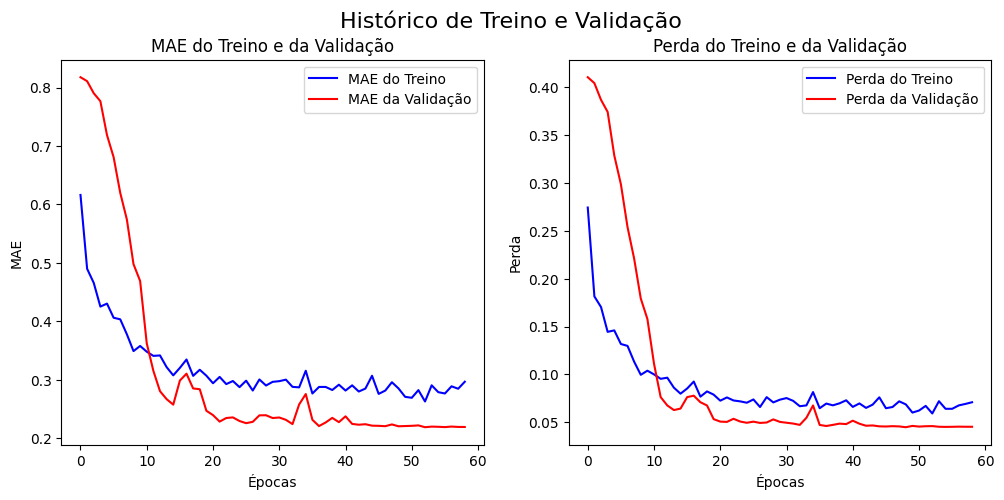

In [ ]:
pred_lstm = model.predict(X_test_lstm)

rmse_lstm = np.sqrt(mean_squared_error(y_test, pred_lstm))

print("RMSE LSTM:", rmse_lstm)

accuracy = history.history['mae']
val_accuracy = history.history['val_mae']

loss = history.history['loss']
val_loss = history.history['val_loss']


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(range(len(accuracy)), accuracy, 'b', label='MAE do Treino')
ax1.plot(range(len(val_accuracy)), val_accuracy, 'r', label='MAE da Validação')
ax1.set_title('MAE do Treino e da Validação')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('MAE')
ax1.legend()

ax2.plot(range(len(accuracy)), loss, 'b', label='Perda do Treino')
ax2.plot(range(len(val_accuracy)), val_loss, 'r', label='Perda da Validação')
ax2.set_title('Perda do Treino e da Validação')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Perda')
ax2.legend()

fig.suptitle('Histórico de Treino e Validação', fontsize=16)
plt.show()

In [ ]:
print(df['SPI3'].describe())

count    1450.000000
mean       -0.004622
std         1.015834
min        -1.345000
25%        -1.032250
50%        -0.068500
75%         0.905500
max         2.972000
Name: SPI3, dtype: float64


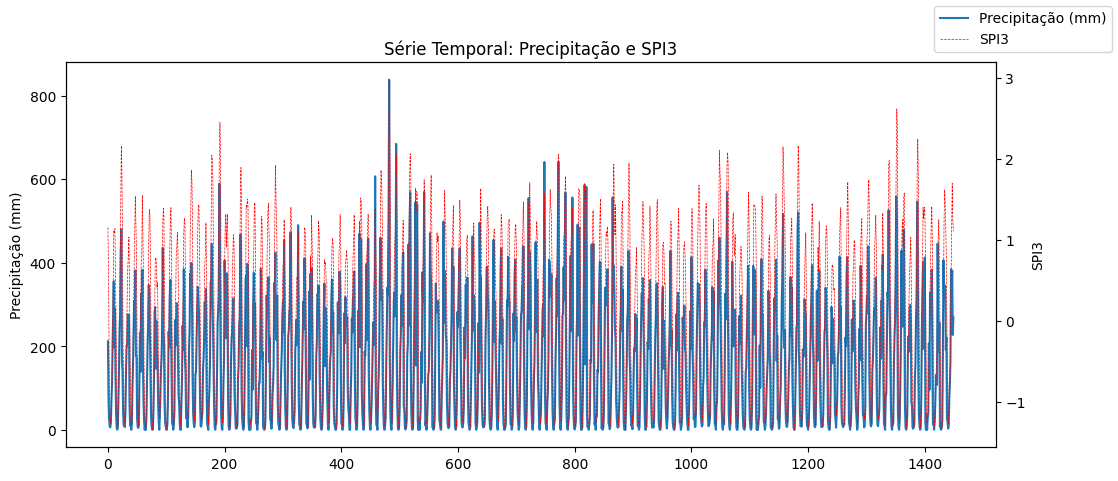

In [ ]:
fig, ax1 = plt.subplots(figsize=(12,5))

# eixo da precipitação
ax1.plot(df['prec'], label='Precipitação (mm)')
ax1.set_ylabel('Precipitação (mm)')

# eixo do SPI
ax2 = ax1.twinx()
ax2.plot(df['SPI3'], linestyle='--', label='SPI3', color = 'red',linewidth=0.5)
ax2.set_ylabel('SPI3')

plt.title('Série Temporal: Precipitação e SPI3')

fig.legend(loc='upper right')
plt.show()

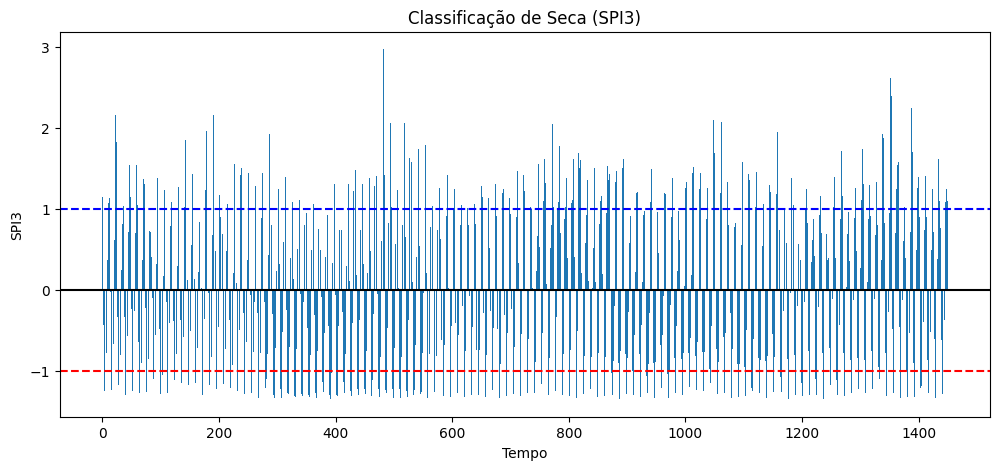

In [ ]:
plt.figure(figsize=(12,5))

plt.bar(df.index, df['SPI3'])

plt.axhline(0, color='black')
plt.axhline(-1, color='red', linestyle='--')
plt.axhline(1, color='blue', linestyle='--')

plt.title('Classificação de Seca (SPI3)')
plt.xlabel('Tempo')
plt.ylabel('SPI3')

plt.show()

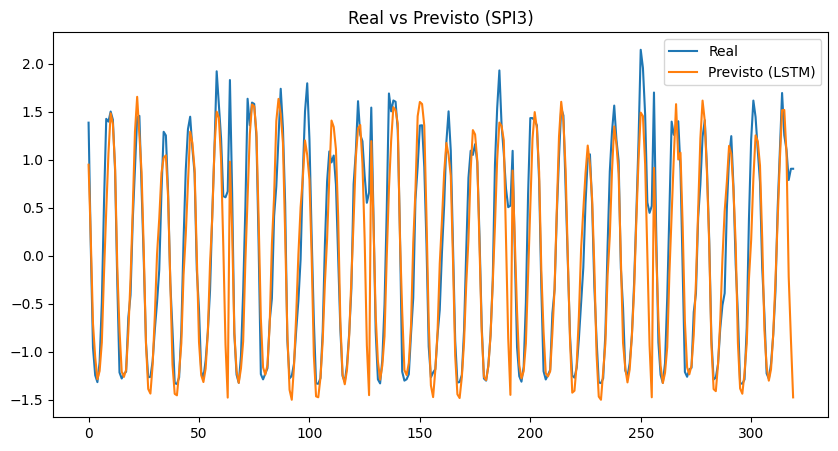

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(y_test.values, label='Real')
plt.plot(pred_lstm, label='Previsto (LSTM)')

plt.title('Real vs Previsto (SPI3)')
plt.legend()
plt.show()

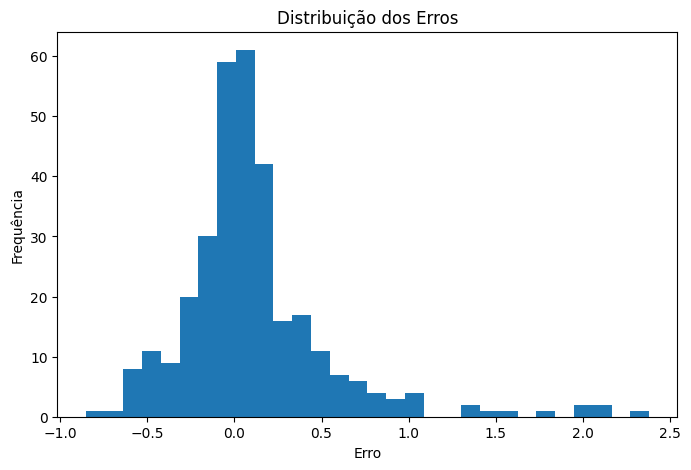

In [ ]:
erro = y_test.values - pred_lstm.flatten()

plt.figure(figsize=(8,5))
plt.hist(erro, bins=30)

plt.title('Distribuição dos Erros')
plt.xlabel('Erro')
plt.ylabel('Frequência')

plt.show()

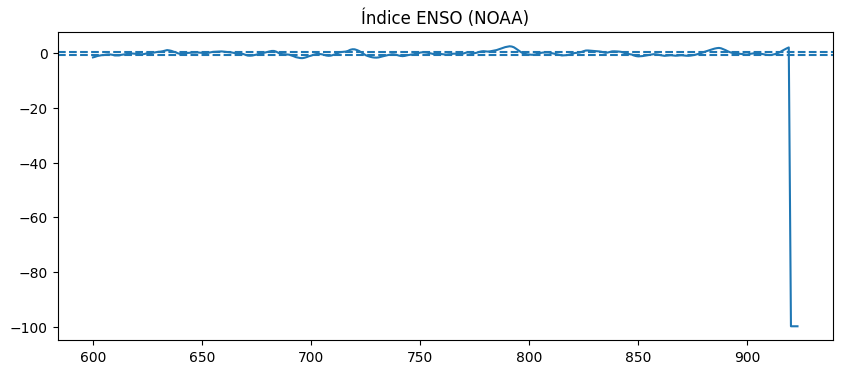

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df_enso['ENSO'])
plt.title("Índice ENSO (NOAA)")
plt.axhline(0.5, linestyle='--')
plt.axhline(-0.5, linestyle='--')
plt.show()

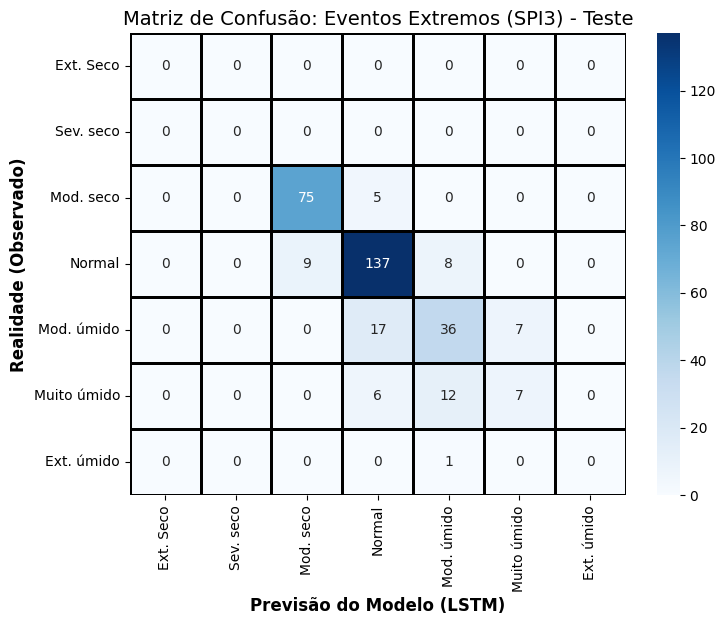


--- Relatório de Classificação de Secas/Cheias ---
              precision    recall  f1-score   support

   Ext. Seco       0.00      0.00      0.00         0
   Sev. seco       0.00      0.00      0.00         0
   Mod. seco       0.89      0.94      0.91        80
      Normal       0.83      0.89      0.86       154
  Mod. úmido       0.63      0.60      0.62        60
 Muito úmido       0.50      0.28      0.36        25
  Ext. úmido       0.00      0.00      0.00         1

    accuracy                           0.80       320
   macro avg       0.41      0.39      0.39       320
weighted avg       0.78      0.80      0.79       320



In [ ]:
def categorizar_spi(valor):
    if valor >= 2.0:
        return 'Ext. úmido'
    elif valor >= 1.5:
        return 'Muito úmido'
    elif valor >= 1.0:
        return 'Mod. úmido'
    elif valor > -1.0:
        return 'Normal'
    elif valor > -1.5:
        return 'Mod. seco'
    elif valor > -2.0:
        return 'Sev. seco'
    else:
        return 'Ext. Seco'

y_test_classes = [categorizar_spi(v) for v in y_test.values]
pred_classes = [categorizar_spi(v) for v in pred_lstm.flatten()]

labels = [
    'Ext. Seco',
    'Sev. seco',
    'Mod. seco',
    'Normal',
    'Mod. úmido',
    'Muito úmido',
    'Ext. úmido'
]

cm = confusion_matrix(y_test_classes, pred_classes, labels=labels)


plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels,
            linewidths=1, linecolor='black')

plt.title('Matriz de Confusão: Eventos Extremos (SPI3) - Teste', fontsize=14)
plt.xlabel('Previsão do Modelo (LSTM)', fontsize=12, fontweight='bold')
plt.ylabel('Realidade (Observado)', fontsize=12, fontweight='bold')
plt.show()

print("\n--- Relatório de Classificação de Secas/Cheias ---")
print(classification_report(y_test_classes, pred_classes, labels=labels))

# **Painel da Previsão**

In [ ]:
def previsao_hidrica(ano_base, mes_base, ponto_id):
  dados_base = df[(df['ano'] == ano_base) & (df['mes'] == mes_base) & (df['ponto'] == ponto_id)]

  if dados_base.empty:
        print(f"Erro: Dados não encontrados.")
        return

  X_novo = dados_base[lag_features + extra_features]
  X_novo_scaled = scaler.transform(X_novo)
  X_novo_lstm = X_novo_scaled.reshape((1, X_novo_scaled.shape[1], 1))

  previsao_spi3 = model.predict(X_novo_lstm, verbose=0)[0][0]

  mes_futuro = mes_base + 3
  ano_futuro = ano_base
  if mes_futuro > 12:
      mes_futuro -= 12
      ano_futuro += 1

  print(f"Ponto Analisado : {ponto_id}")
  print(f"Dados Base      : {mes_base}/{ano_base}")
  print(f"Previsão Alvo   : {mes_futuro}/{ano_futuro} (Daqui a 3 meses)")
  print(f"Valor do SPI-3  : {previsao_spi3:.3f}")


  if previsao_spi3 <= -1.5:
        print("Tendência de Seca Severa/Extrema. Acionar contingência de irrigação.")

  elif -1.5 < previsao_spi3 <= -1.0:
      print("Tendência de Seca Moderada. Fique atento à umidade do solo.")

  elif 1.0 <= previsao_spi3 < 1.5:
      print("Tendência de chuvas acima da média. Risco para operações.")

  elif previsao_spi3 >= 1.5:
      print("Risco de excesso hídrico / alagamentos no talhão.")

  else:
      print("Tendência de normalidade climática para a janela.")


previsao_hidrica(ano_base = 2026, mes_base = 4, ponto_id =4)

Ponto Analisado : 4
Dados Base      : 4/2026
Previsão Alvo   : 7/2026 (Daqui a 3 meses)
Valor do SPI-3  : -1.134
Tendência de Seca Moderada. Fique atento à umidade do solo.


# Analise de Dados


--- TABELA ANOVA ---
                sum_sq      df         F  PR(>F)  % Variância Explicada (Eta²)
ndvi          175.1555     1.0  378.2159  0.0000                       18.4371
temp           87.5298     1.0  189.0045  0.0000                        9.2135
ENSO            0.2528     1.0    0.5459  0.4601                        0.0266
lst_landsat     7.4449     1.0   16.0759  0.0001                        0.7837
ndvi_landsat   10.9004     1.0   23.5375  0.0000                        1.1474
heat_wave          NaN     1.0       NaN     NaN                           NaN
Residual      668.7305  1444.0       NaN     NaN                       70.3917


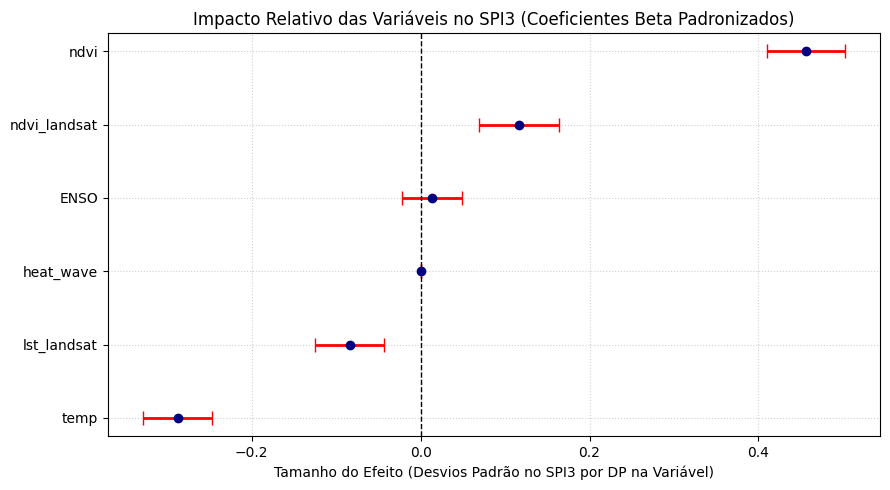

In [ ]:
# =============================================================================
# 1. ANÁLISE GERAL E EXPORTAÇÃO DA TABELA ANOVA
# =============================================================================
features = ['ndvi', 'temp', 'ENSO', 'lst_landsat', 'ndvi_landsat', 'heat_wave']
X = df[features].dropna()
y = df.loc[X.index, 'SPI3']

# Padronizar preditores e montar DataFrame
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)
df_reg = pd.concat([y, X_scaled], axis=1)

# Ajustar modelo geral via OLS
formula = 'SPI3 ~ ' + ' + '.join(features)
modelo_ols = smf.ols(formula, data=df_reg).fit()

# Gerar e Exportar Tabela ANOVA
tabela_anova = anova_lm(modelo_ols, typ=2)
tabela_anova['% Variância Explicada (Eta²)'] = (tabela_anova['sum_sq'] / tabela_anova['sum_sq'].sum()) * 100
print("\n--- TABELA ANOVA ---")
print(tabela_anova.round(4))

# EXPORTAÇÃO DA ANOVA
tabela_anova.to_csv('/content/drive/MyDrive/Tabela_ANOVA_Geral.csv', index=True)

# Gráfico de Coeficientes Gerais
params = modelo_ols.params.drop('Intercept', errors='ignore')
conf = modelo_ols.conf_int().drop('Intercept', errors='ignore')
conf.columns = ['ci_lower', 'ci_upper']

df_coef = pd.DataFrame({
    'Coeficiente': params,
    'ci_lower': conf['ci_lower'],
    'ci_upper': conf['ci_upper']
}).sort_values(by='Coeficiente')

plt.figure(figsize=(9, 5))
plt.errorbar(
    df_coef['Coeficiente'], df_coef.index,
    xerr=[df_coef['Coeficiente'] - df_coef['ci_lower'], df_coef['ci_upper'] - df_coef['Coeficiente']],
    fmt='o', color='navy', ecolor='red', elinewidth=2, capsize=5
)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title('Impacto Relativo das Variáveis no SPI3 (Coeficientes Beta Padronizados)', fontsize=12)
plt.xlabel('Tamanho do Efeito (Desvios Padrão no SPI3 por DP na Variável)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

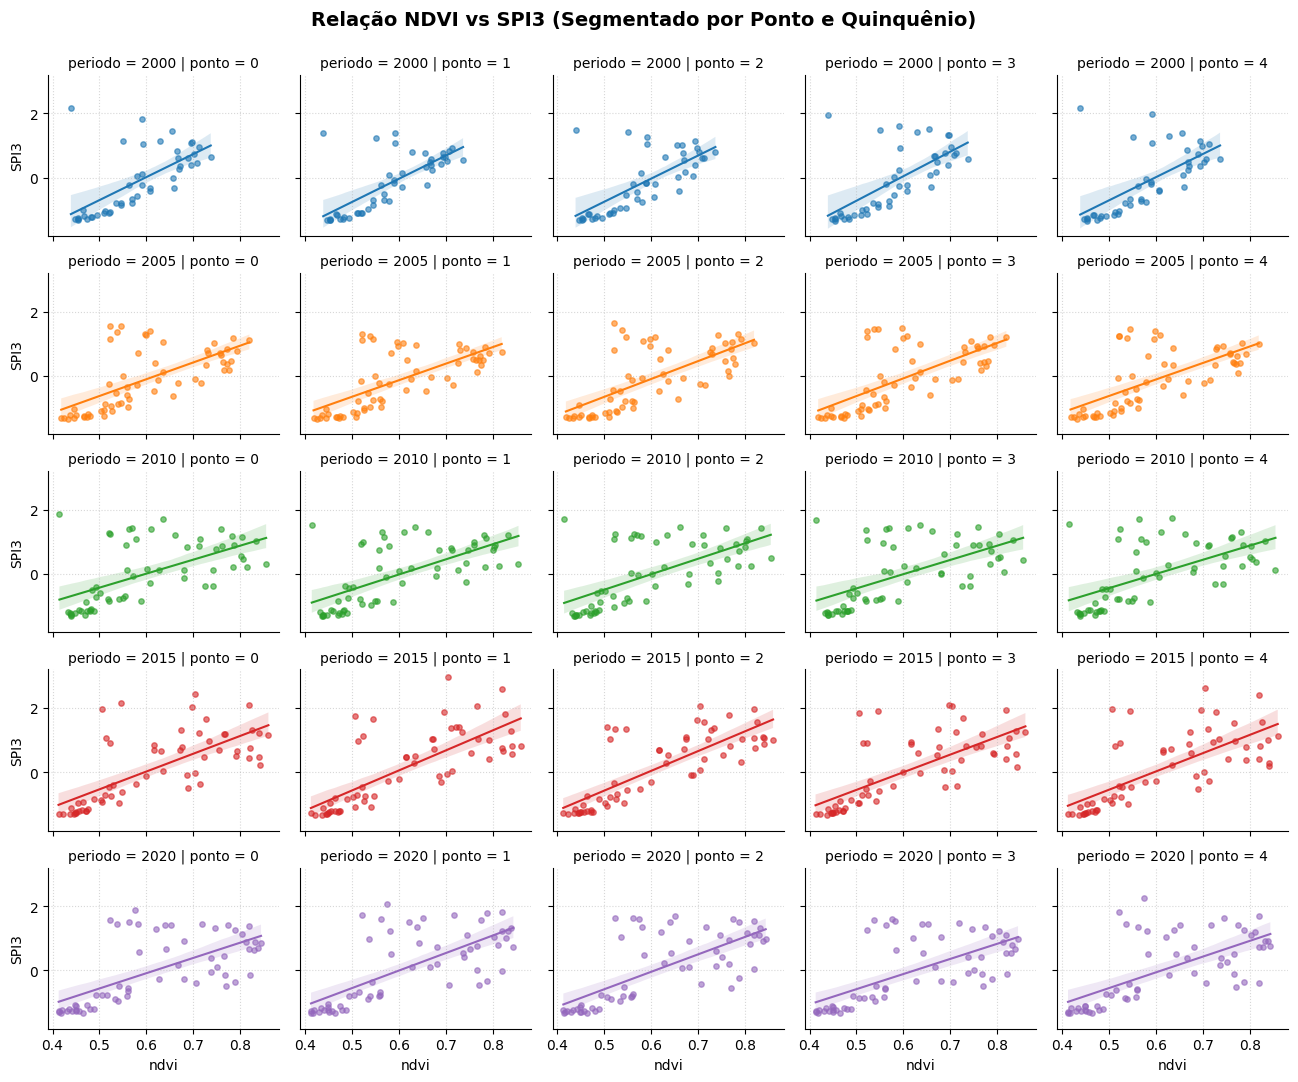

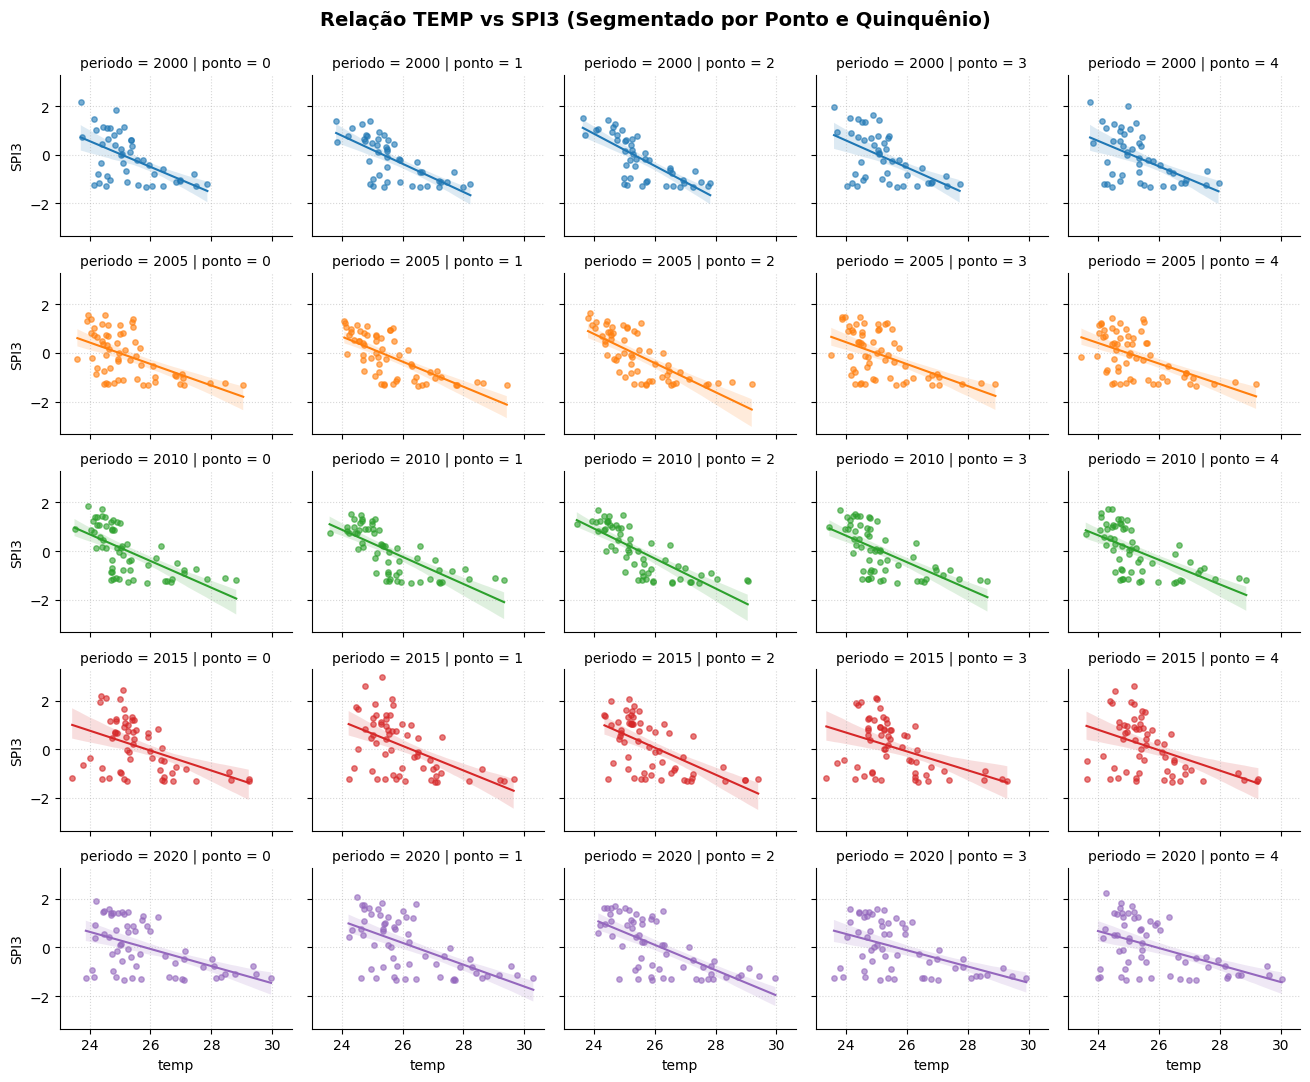

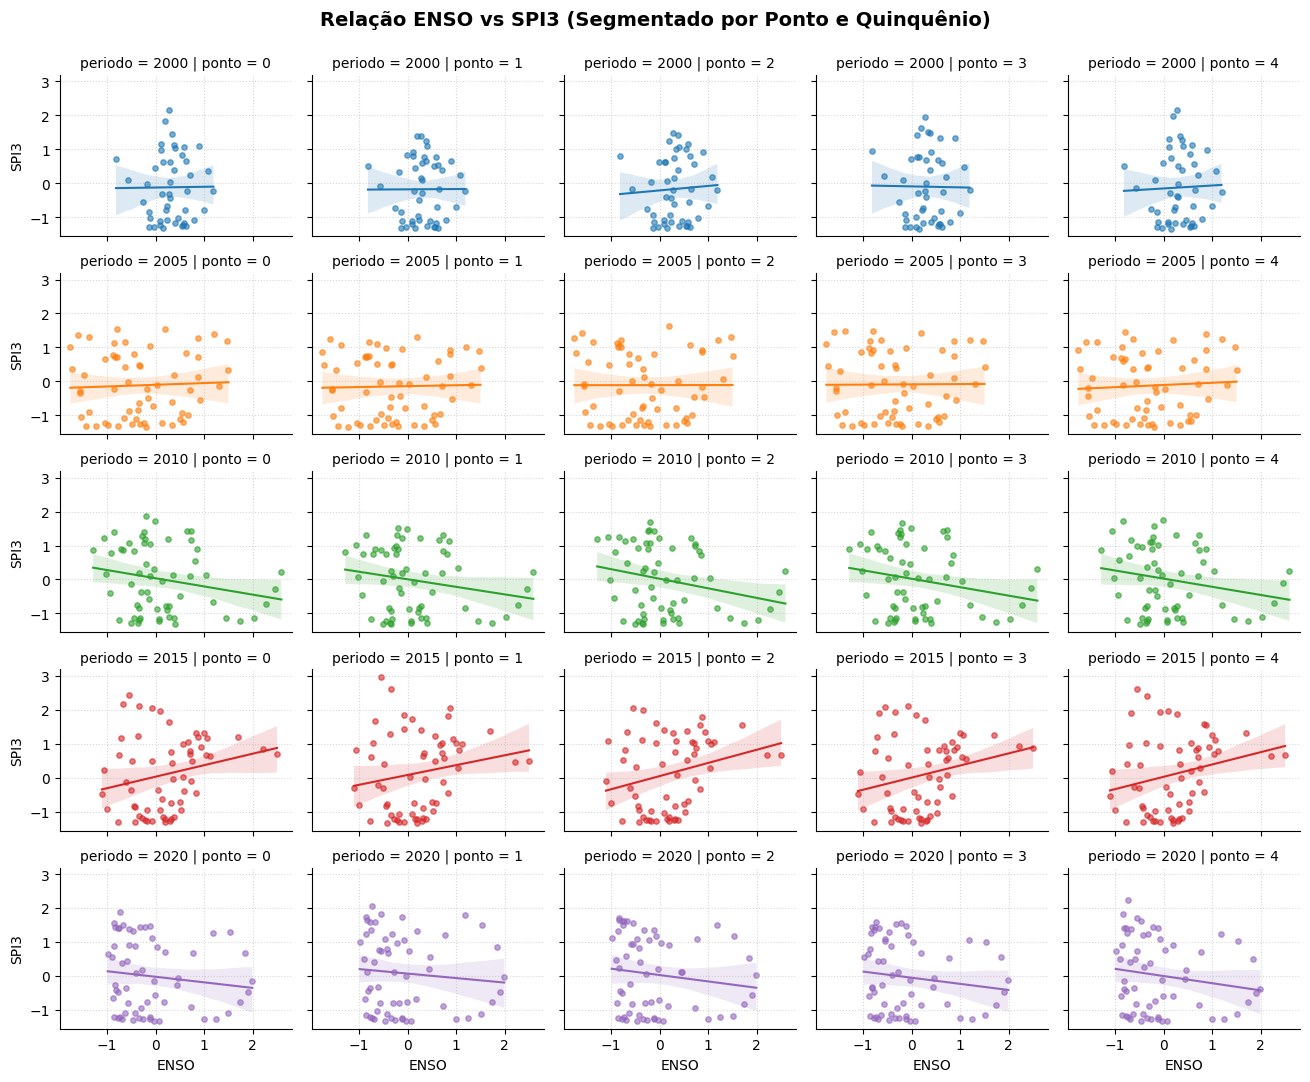

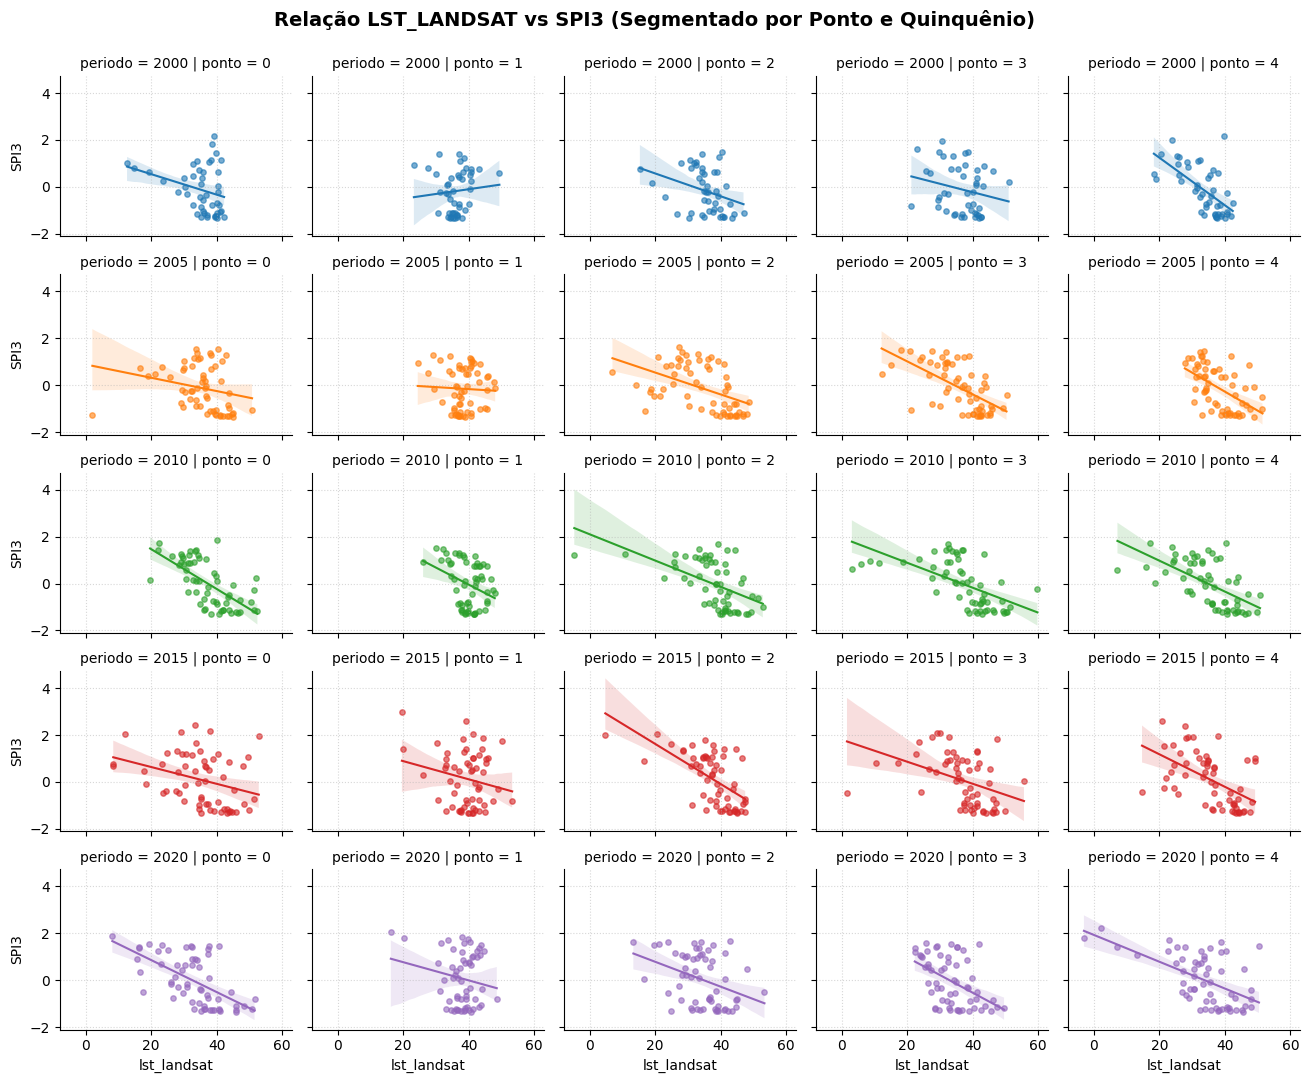

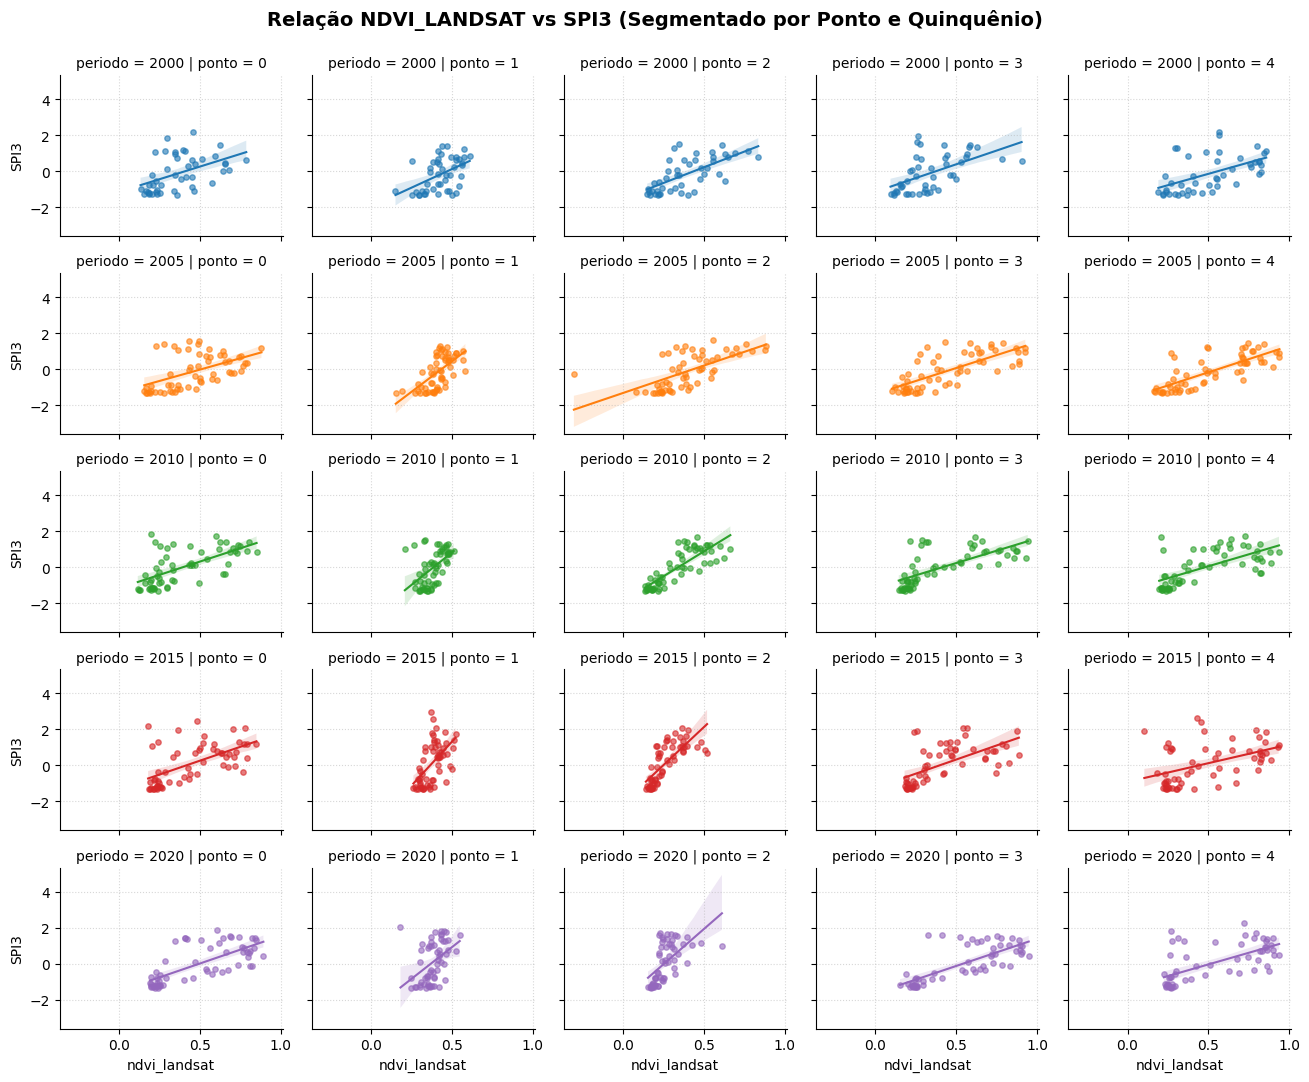

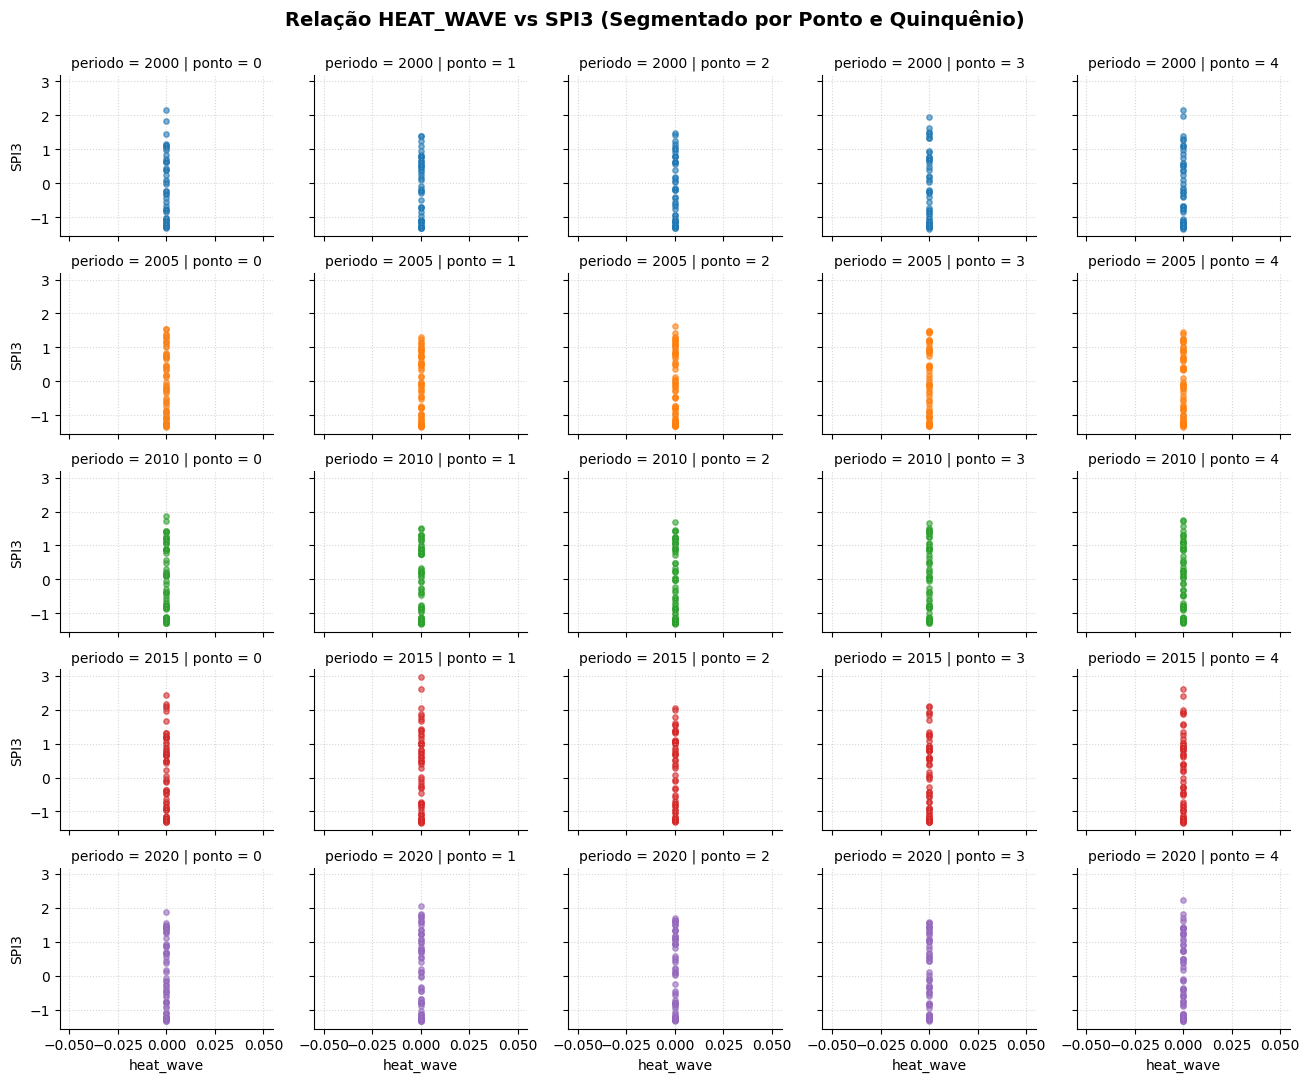

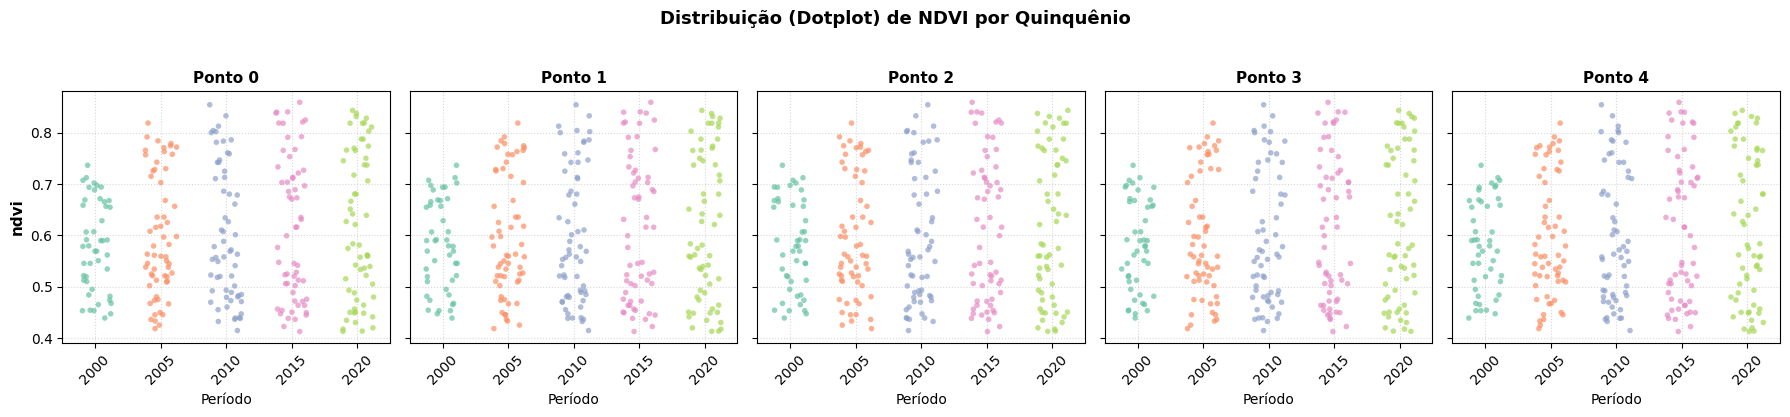

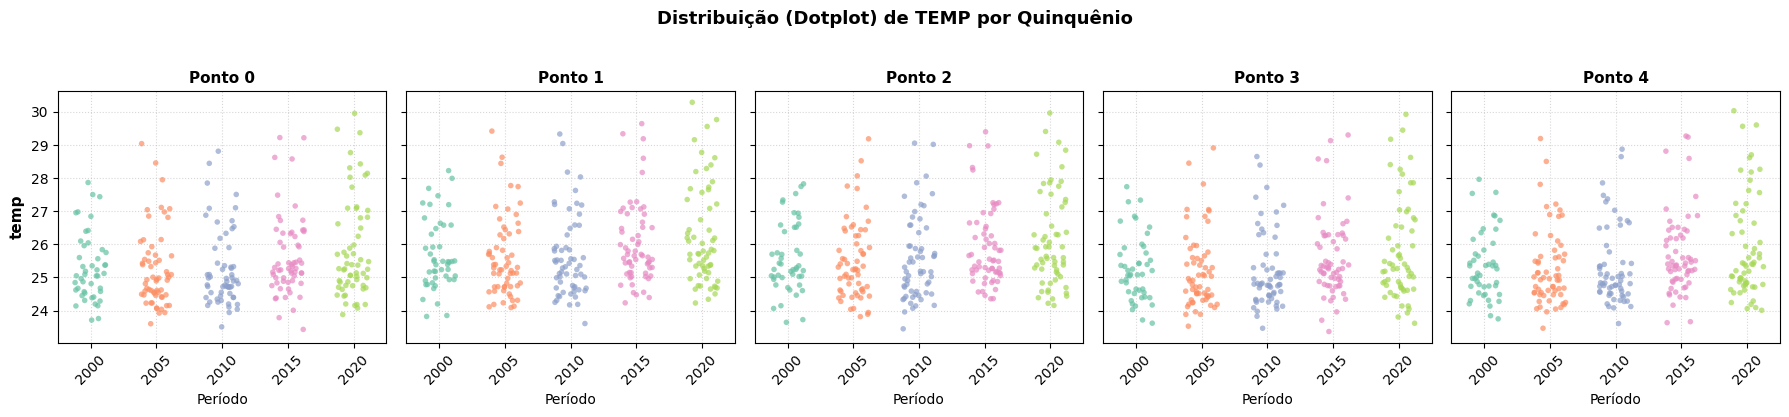

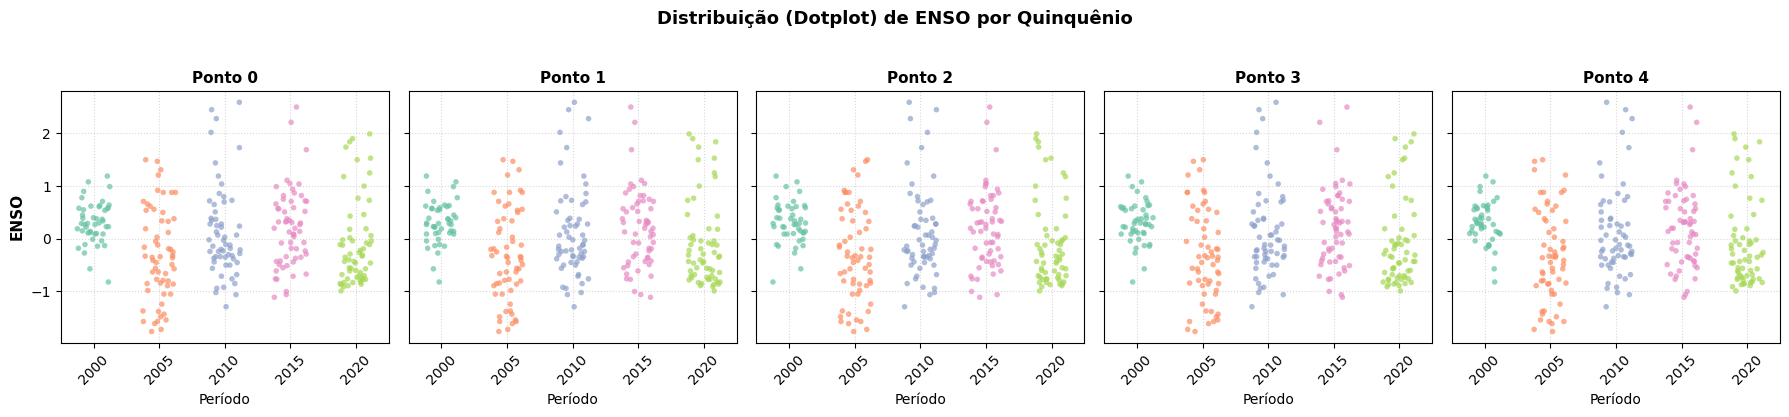

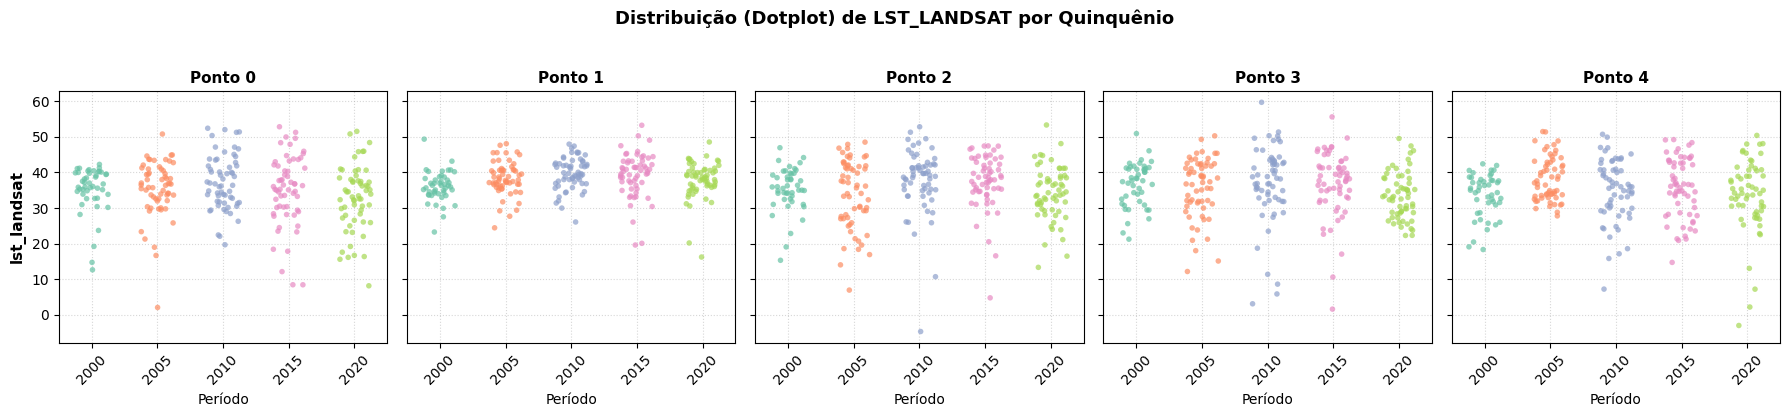

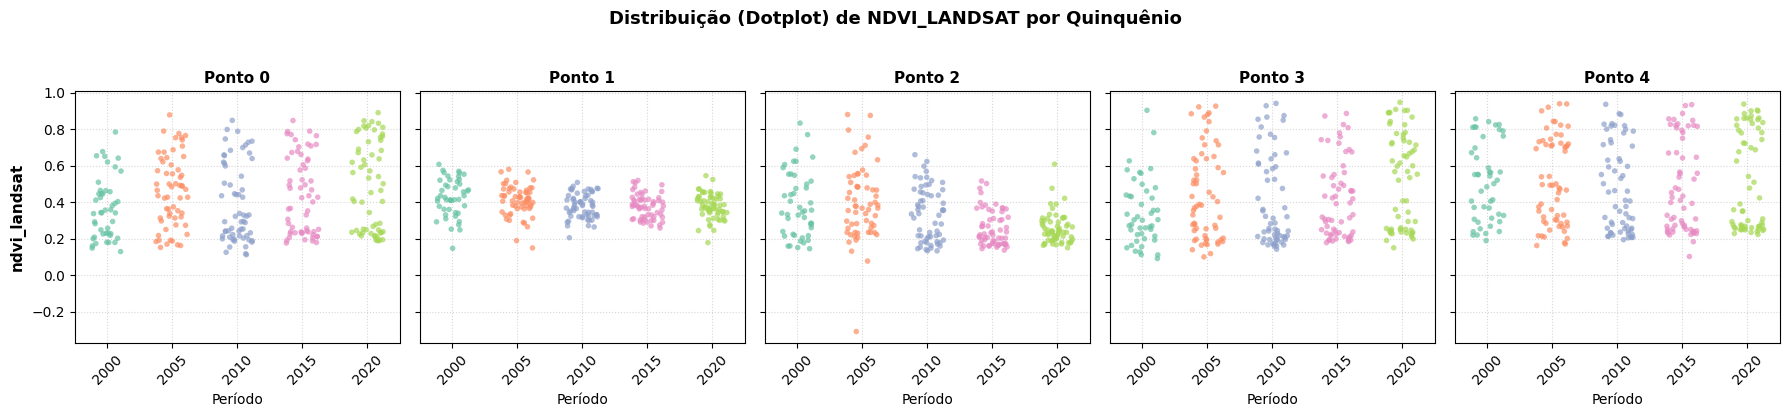

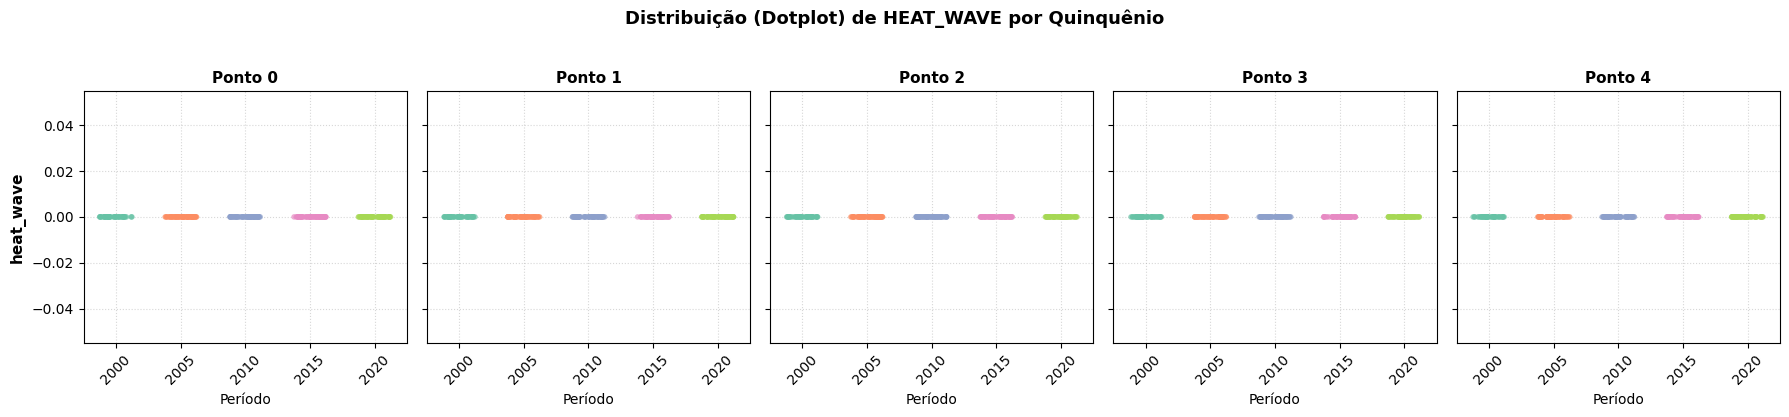

In [ ]:
# =============================================================================
# 2. DEFINIÇÃO DOS QUINQUÊNIOS E VISUALIZAÇÕES ESPACIAIS
# =============================================================================
bins = [2000, 2005, 2010, 2015, 2020, 2025]
rotulos = ['2000', '2005', '2010', '2015', '2020']
df['periodo'] = pd.cut(df['ano'], bins=bins, labels=rotulos)


# Grade de Regressão (Scatter)
for var in features:
    g = sns.lmplot(
        data=df, x=var, y='SPI3', col='ponto', row='periodo', hue='periodo',
        palette='tab10', height=2.2, aspect=1.2,
        scatter_kws={'alpha': 0.6, 's': 15}, line_kws={'linewidth': 1.5}
    )
    g.fig.subplots_adjust(top=0.92)
    g.fig.suptitle(f'Relação {var.upper()} vs SPI3 (Segmentado por Ponto e Quinquênio)', fontsize=14, fontweight='bold')
    g.set_axis_labels(var, 'SPI3')
    for ax in g.axes.flat:
        ax.grid(True, linestyle=':', alpha=0.5)
    plt.show()

# Distribuição de Frequência (Dotplot)
for var in features:
    fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)
    pontos_unicos = sorted(df['ponto'].unique())
    for i, p in enumerate(pontos_unicos):
        df_ponto = df[df['ponto'] == p]
        sns.stripplot(
            data=df_ponto, x='periodo', y=var, hue='periodo', ax=axes[i],
            jitter=0.25, size=4, alpha=0.7, palette='Set2', legend=False
        )
        axes[i].set_title(f'Ponto {p}', fontsize=11, fontweight='bold')
        axes[i].set_xlabel('Período')
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].grid(True, linestyle=':', alpha=0.5)
        if i == 0:
            axes[i].set_ylabel(var, fontsize=11, fontweight='bold')
    plt.suptitle(f'Distribuição (Dotplot) de {var.upper()} por Quinquênio', fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

In [ ]:
# =============================================================================
# 3. REGRESSÃO QUINQUENAL SEPARADA POR PONTO DE ESTUDO (COM EXPORTAÇÃO)
# =============================================================================
resultados_reg_pontos = []
pontos_unicos = sorted(df['ponto'].unique())

for ponto in pontos_unicos:
    for periodo in rotulos:
        df_sub = df[(df['ponto'] == ponto) & (df['periodo'] == periodo)].dropna(subset=features + ['SPI3']).copy()

        if len(df_sub) > 10:
            valid_features = [f for f in features if df_sub[f].std() > 0]
            if valid_features:
                scaler = StandardScaler()
                df_sub[valid_features] = scaler.fit_transform(df_sub[valid_features])

                formula = 'SPI3 ~ ' + ' + '.join(valid_features)
                modelo = smf.ols(formula, data=df_sub).fit()

                for var in valid_features:
                    resultados_reg_pontos.append({
                        'Ponto': ponto,
                        'Período': periodo,
                        'Variável': var,
                        'Coeficiente_Beta': modelo.params[var],
                        'p_valor': modelo.pvalues[var],
                        'Significativo': 'Sim (p < 0.05)' if modelo.pvalues[var] < 0.05 else 'Não',
                        'R2_Ajustado': modelo.rsquared_adj
                    })

df_resultados_pontos = pd.DataFrame(resultados_reg_pontos)

# EXPORTAÇÃO POR PONTO E PERÍODO (Todos os pontos)
df_resultados_pontos.to_csv('/content/drive/MyDrive/Regressao_SPI3_Por_Ponto_e_PeriodovFinal.csv', index=False)

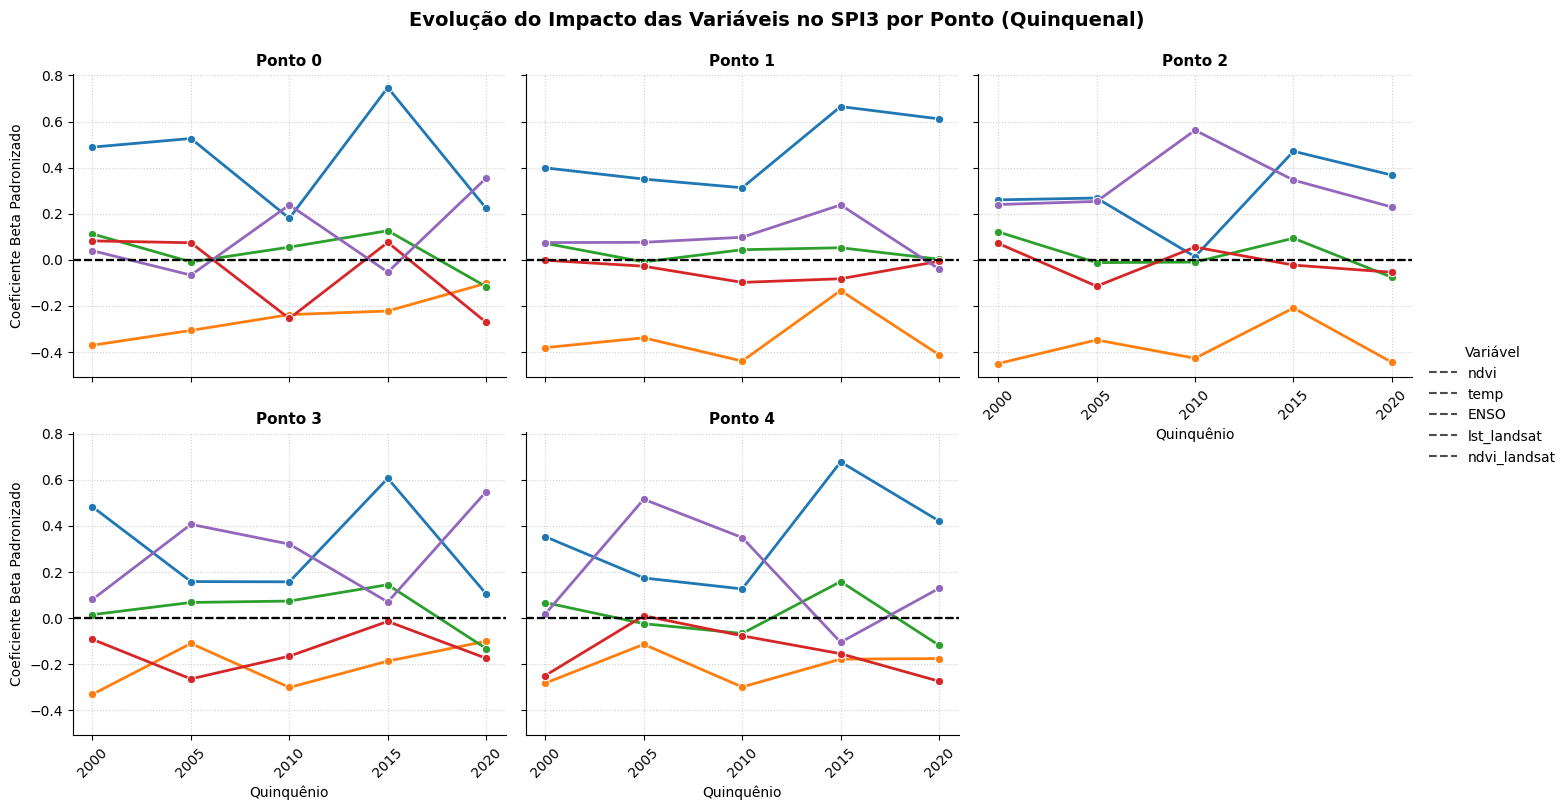

In [ ]:
# Gráfico Evolução por Ponto
g_pontos = sns.FacetGrid(df_resultados_pontos, col='Ponto', hue='Variável', col_wrap=3, height=4, aspect=1.2)
g_pontos.map(sns.lineplot, 'Período', 'Coeficiente_Beta', marker='o', linewidth=2)
g_pontos.map(plt.axhline, y=0, color='black', linestyle='--', alpha=0.7)
g_pontos.add_legend(title='Variável')
g_pontos.set_titles(col_template="Ponto {col_name}", size=11, weight='bold')
g_pontos.set_axis_labels("Quinquênio", "Coeficiente Beta Padronizado")
for ax in g_pontos.axes.flat:
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle=':', alpha=0.6)
plt.subplots_adjust(top=0.9)
g_pontos.fig.suptitle('Evolução do Impacto das Variáveis no SPI3 por Ponto (Quinquenal)', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
# =============================================================================
# 4. REGRESSÃO MENSAL QUINQUENAL (PONTOS AGRUPADOS) COM EXPORTAÇÃO
# =============================================================================
resultados_mensais = []
nomes_meses = {1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
               7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'}

for periodo in rotulos:
    for mes_num in range(1, 13):
        df_sub = df[(df['periodo'] == periodo) & (df['mes'] == mes_num)].dropna(subset=features + ['SPI3']).copy()
        valid_features = [f for f in features if df_sub[f].std() > 0]

        if len(df_sub) > len(valid_features) + 2 and len(valid_features) > 0:
            scaler = StandardScaler()
            df_sub[valid_features] = scaler.fit_transform(df_sub[valid_features])

            formula = 'SPI3 ~ ' + ' + '.join(valid_features)
            modelo = smf.ols(formula, data=df_sub).fit()

            for var in valid_features:
                resultados_mensais.append({
                    'Período': periodo,
                    'Mês_Num': mes_num,
                    'Mês': nomes_meses[mes_num],
                    'Variável': var,
                    'Coeficiente_Beta': modelo.params[var],
                    'p_valor': modelo.pvalues[var],
                    'Significativo': 'Sim (p < 0.05)' if modelo.pvalues[var] < 0.05 else 'Não',
                    'R2_Ajustado': modelo.rsquared_adj,
                    'N_Amostras': len(df_sub)
                })

df_res_mensal = pd.DataFrame(resultados_mensais)

# EXPORTAÇÃO POR MÊS E PERÍODO
df_res_mensal.to_csv('/content/drive/MyDrive/Regressao_SPI3_Por_Mes_e_Periodo.csv', index=False)

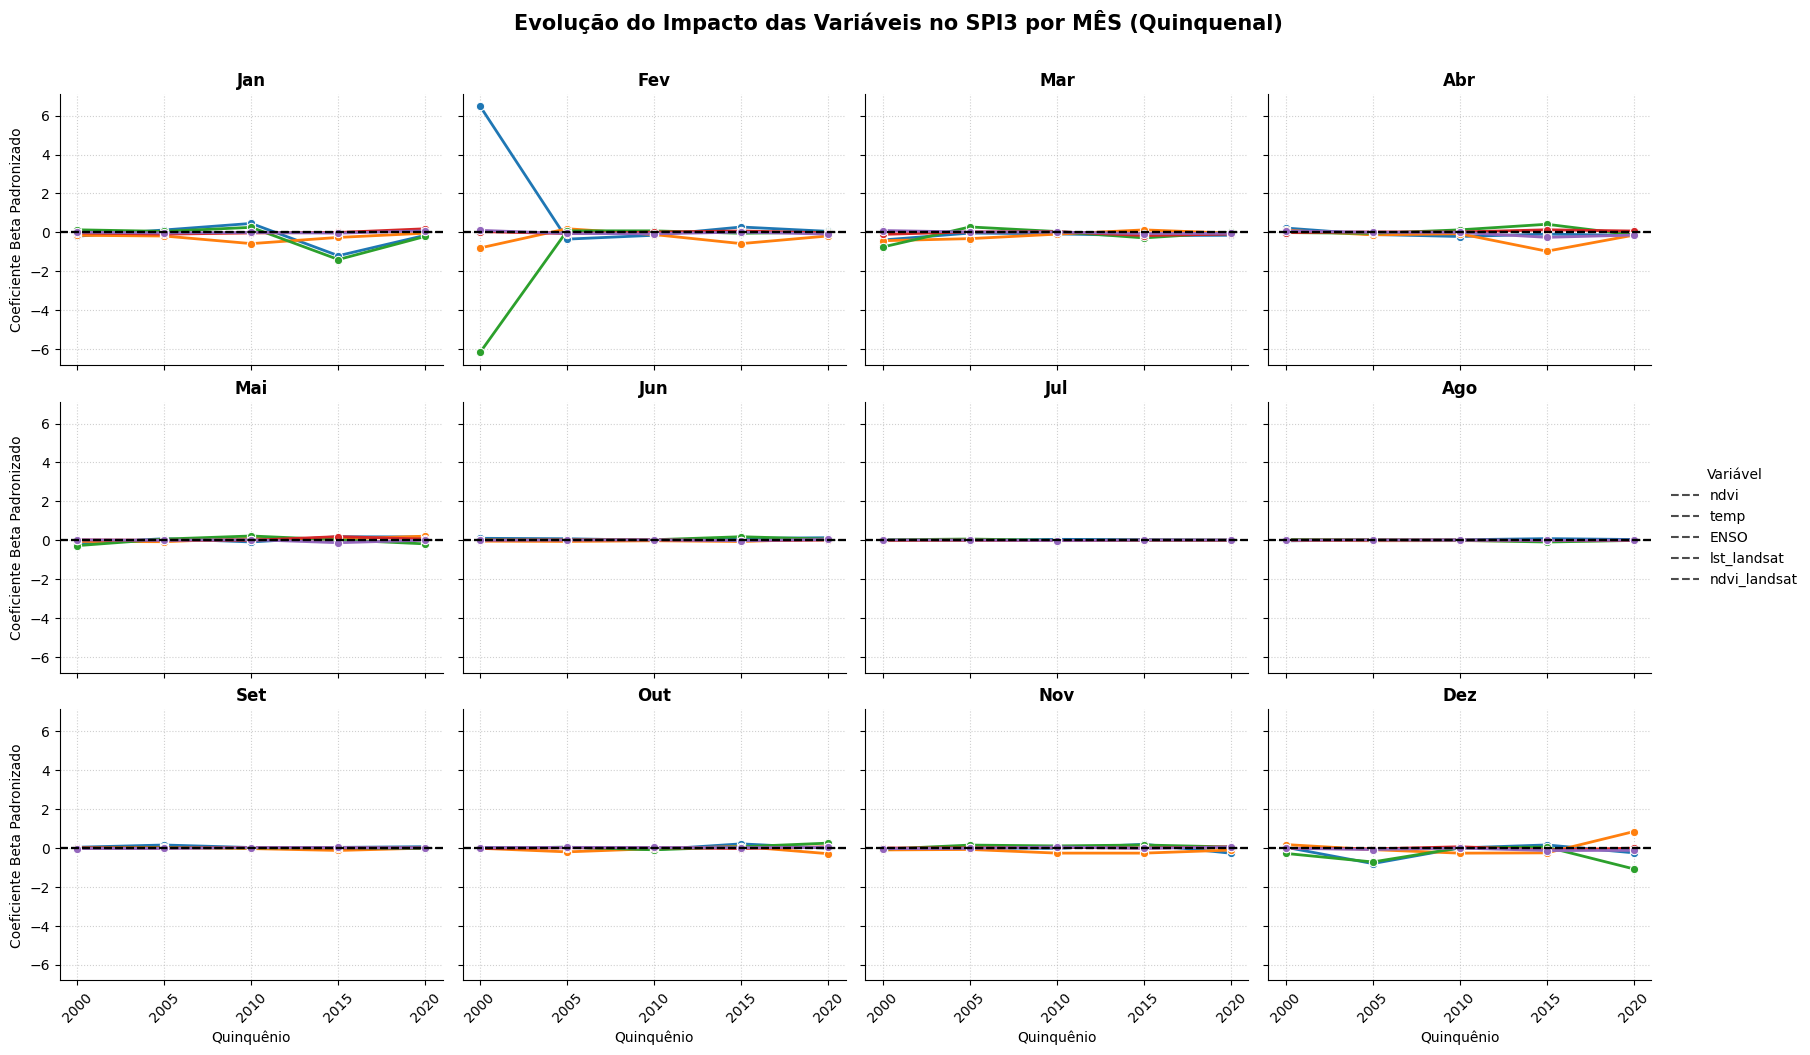

In [ ]:
# Gráfico Evolução por Mês (Corrigido col='Mês')
g_mes = sns.FacetGrid(
    df_res_mensal, col='Mês', hue='Variável', col_wrap=4, height=3.5, aspect=1.2,
    col_order=['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
)
g_mes.map(sns.lineplot, 'Período', 'Coeficiente_Beta', marker='o', linewidth=2)
g_mes.map(plt.axhline, y=0, color='black', linestyle='--', alpha=0.7)
g_mes.add_legend(title='Variável')
g_mes.set_titles(col_template="{col_name}", size=12, weight='bold') # Corrigido o título das caixinhas
g_mes.set_axis_labels("Quinquênio", "Coeficiente Beta Padronizado")
for ax in g_mes.axes.flat:
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle=':', alpha=0.6)
plt.subplots_adjust(top=0.9)
g_mes.fig.suptitle('Evolução do Impacto das Variáveis no SPI3 por MÊS (Quinquenal)', fontsize=15, fontweight='bold')
plt.show()

In [ ]:
features = ['ndvi', 'temp', 'ENSO', 'lst_landsat', 'ndvi_landsat', 'heat_wave']

# Remoção de valores nulos e preparação do dataset
df_clean = df.dropna(subset=features + ['SPI3']).copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(df_clean[features]), columns=features, index=df_clean.index)
y = df_clean['SPI3']

#-- ETAPA CRÍTICA: O Statsmodels exige a adição explícita de uma coluna de intercepto (constante).
X = sm.add_constant(X_scaled)

#-- Ajuste o modelo de Mínimos Quadrados Ordinários (MQO)
model = sm.OLS(y, X).fit()

#-- 5. Imprime o resumo estatístico contendo os p-valores
print(model.summary())

# Salvar o resumo textual completo no Google Drive
with open('/content/drive/MyDrive/OLS_Regression_Results_Summary.txt', 'w') as f:
    f.write(model.summary().as_text())

# Tabela resumo dos Coeficientes Individuais
df_coef_geral = pd.DataFrame({
    'Coeficiente_Beta': model.params.drop('const'),
    'Erro_Padrao': model.bse.drop('const'),
    'p_valor': model.pvalues.drop('const'),
    'Significativo_p05': model.pvalues.drop('const') < 0.05,
    'CI_Lower': model.conf_int().drop('const')[0],
    'CI_Upper': model.conf_int().drop('const')[1]
}).sort_values(by='Coeficiente_Beta', ascending=False)

                            OLS Regression Results                            
Dep. Variable:                   SPI3   R-squared:                       0.553
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     356.9
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          2.94e-249
Time:                        17:02:42   Log-Likelihood:                -1496.4
No. Observations:                1450   AIC:                             3005.
Df Residuals:                    1444   BIC:                             3036.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0046      0.018     -0.259   

In [ ]:
# =============================================================================
# COMPARAÇÃO DE MODELOS: COM VS SEM DETERMINADAS VARIÁVEIS
# =============================================================================

# 1. Definir os dois conjuntos de variáveis que você quer testar
features_full = ['ndvi', 'temp', 'ENSO', 'lst_landsat', 'ndvi_landsat', 'heat_wave']
features_reduced = ['ndvi', 'temp', 'lst_landsat', 'ndvi_landsat', 'heat_wave'] # Exemplo: removendo as variáveis Landsat e heat_wave

# 2. Ajustar o Modelo Completo
X_full = sm.add_constant(X_scaled[features_full])
model_full = sm.OLS(y, X_full).fit()

# 3. Ajustar o Modelo Reduzido (sem as variáveis excluídas)
X_reduced = sm.add_constant(X_scaled[features_reduced])
model_reduced = sm.OLS(y, X_reduced).fit()

# 4. Tabela Comparativa de Métricas (R², AIC, BIC)
tabela_comparacao = pd.DataFrame({
    'Modelo': ['Completo (Todas as Variáveis)', 'Reduzido (Seleção)'],
    'R²': [model_full.rsquared, model_reduced.rsquared],
    'R² Ajustado': [model_full.rsquared_adj, model_reduced.rsquared_adj],
    'AIC': [model_full.aic, model_reduced.aic],
    'BIC': [model_full.bic, model_reduced.bic]
})

print("\n--- COMPARAÇÃO DE DESEMPENHO DOS MODELOS ---")
print(tabela_comparacao.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 5. Teste F (ANOVA) para verificar se a remoção das variáveis prejudica significativamente o modelo
# Nota: Funciona se o modelo reduzido for um subconjunto direto do completo.
f_stat, p_val, df_diff = model_full.compare_f_test(model_reduced)

print("\n--- TESTE F (COMPARAÇÃO ESTATÍSTICA) ---")
print(f"Estatística F: {f_stat:.4f}")
print(f"p-valor: {p_val:.4f}")

if p_val < 0.05:
    print("Resultado: A remoção das variáveis causou perda estatisticamente significativa. O modelo COMPLETO é melhor.")
else:
    print("Resultado: Não há diferença estatisticamente significativa. O modelo REDUZIDO é mais parcimonioso e adequado.")


--- COMPARAÇÃO DE DESEMPENHO DOS MODELOS ---
                       Modelo     R²  R² Ajustado       AIC       BIC
Completo (Todas as Variáveis) 0.5528       0.5512 3004.7121 3036.3880
           Reduzido (Seleção) 0.5526       0.5514 3003.2601 3029.6567

--- TESTE F (COMPARAÇÃO ESTATÍSTICA) ---
Estatística F: 0.5459
p-valor: 0.4601
Resultado: Não há diferença estatisticamente significativa. O modelo REDUZIDO é mais parcimonioso e adequado.
